In [13]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nasa/landslide-events/catalog.csv
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_305.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_515.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_619.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_51.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_214.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_572.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_655.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_680.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_677.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_304.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_436.h5
/kaggle/input/datasets/tekbahad

In [14]:
import os, pandas as pd
BASE = '/kaggle/input'
for root, dirs, files in os.walk(BASE, followlinks=True):
    depth = root.replace(BASE, '').count(os.sep)
    if depth <= 6:
        print('  ' * depth + os.path.basename(root) + f'/  ({len(files)} files)')
        for f in files[:4]:
            print('  ' * (depth + 1) + f)
csvs = [os.path.join(r, f) for r, _, fs in os.walk(BASE, followlinks=True) for f in fs if f.lower().endswith('.csv')]
for c in csvs:
    df = pd.read_csv(c, low_memory=False)
    print('\n', c, df.shape)
    print(list(df.columns))

input/  (0 files)
  datasets/  (0 files)
    nasa/  (0 files)
      landslide-events/  (1 files)
        catalog.csv
    tekbahadurkshetri/  (0 files)
      landslide4sense/  (0 files)
        TestData/  (0 files)
          img/  (800 files)
            image_305.h5
            image_515.h5
            image_619.h5
            image_51.h5
        ValidData/  (0 files)
          img/  (245 files)
            image_51.h5
            image_214.h5
            image_143.h5
            image_167.h5
        TrainData/  (0 files)
          mask/  (3799 files)
            mask_65.h5
            mask_1334.h5
            mask_1816.h5
            mask_1898.h5
          img/  (3799 files)
            image_305.h5
            image_2940.h5
            image_2453.h5
            image_515.h5
    pratul007/  (0 files)
      global-landslide-catalog-export/  (1 files)
        Global_Landslide_Catalog_Export.csv

 /kaggle/input/datasets/nasa/landslide-events/catalog.csv (1693, 23)
['id', 'date', 'time', 

In [15]:
import os, glob, json, re, warnings
import numpy as np, pandas as pd, h5py
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

BASE = '/kaggle/input/datasets'
GLC_PATH  = f'{BASE}/pratul007/global-landslide-catalog-export/Global_Landslide_Catalog_Export.csv'
NASA_PATH = f'{BASE}/nasa/landslide-events/catalog.csv'
L4S_PATH  = f'{BASE}/tekbahadurkshetri/landslide4sense'
OUT = '/kaggle/working/stage1'
os.makedirs(OUT, exist_ok=True)

SEED = 42
np.random.seed(SEED)
WG_BBOX   = dict(lat_min=8.0, lat_max=21.5, lon_min=72.5, lon_max=78.0)
WG_STATES = ['kerala', 'karnataka', 'goa', 'maharashtra', 'tamil nadu', 'gujarat']
SW_MONSOON, NE_MONSOON = [6, 7, 8, 9], [10, 11, 12]
RAIN_TRIGGERS = {'rain', 'downpour', 'continuous_rain', 'monsoon', 'tropical_cyclone', 'flooding'}
ACC_KM = {'exact': 0.1, '1km': 1, '5km': 5, '10km': 10, '25km': 25, '50km': 50,
          '100km': 100, '250km': 250, 'unknown': np.nan}

def parse_dates(s, fmts):
    out = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    for f in fmts:
        m = out.isna()
        if m.any():
            out[m] = pd.to_datetime(s[m], format=f, errors='coerce')
    m = out.isna()
    if m.any():
        out[m] = pd.to_datetime(s[m], errors='coerce')
    return out

def norm_trigger(x):
    return 'unknown' if pd.isna(x) else re.sub(r'[\s/]+', '_', str(x).strip().lower())

glc_raw  = pd.read_csv(GLC_PATH,  low_memory=False)
nasa_raw = pd.read_csv(NASA_PATH, low_memory=False)

glc = pd.DataFrame({
    'event_id': glc_raw['event_id'].astype(str),
    'date': parse_dates(glc_raw['event_date'], ['%m/%d/%Y %I:%M:%S %p', '%Y-%m-%d %H:%M:%S', '%Y-%m-%d']),
    'lat': pd.to_numeric(glc_raw['latitude'], errors='coerce'),
    'lon': pd.to_numeric(glc_raw['longitude'], errors='coerce'),
    'country': glc_raw['country_name'], 'admin': glc_raw['admin_division_name'],
    'trigger': glc_raw['landslide_trigger'].map(norm_trigger),
    'category': glc_raw['landslide_category'], 'size': glc_raw['landslide_size'],
    'fatalities': pd.to_numeric(glc_raw['fatality_count'], errors='coerce'),
    'loc_accuracy': glc_raw['location_accuracy'].astype(str).str.lower().str.strip(),
    'source': 'GLC'})
glc['acc_km'] = glc['loc_accuracy'].map(ACC_KM)

nasa = pd.DataFrame({
    'event_id': 'N' + nasa_raw['id'].astype(str),
    'date': parse_dates(nasa_raw['date'], ['%m/%d/%y', '%m/%d/%Y']),
    'lat': pd.to_numeric(nasa_raw['latitude'], errors='coerce'),
    'lon': pd.to_numeric(nasa_raw['longitude'], errors='coerce'),
    'country': nasa_raw['country_name'], 'admin': nasa_raw['state/province'],
    'trigger': nasa_raw['trigger'].map(norm_trigger),
    'category': nasa_raw['landslide_type'], 'size': nasa_raw['landslide_size'],
    'fatalities': pd.to_numeric(nasa_raw['fatalities'], errors='coerce'),
    'loc_accuracy': 'unknown', 'source': 'NASA2016'})
nasa['acc_km'] = np.nan

for name, d in [('GLC', glc), ('NASA2016', nasa)]:
    print(f"{name}: {len(d)} rows | {d['date'].min()} -> {d['date'].max()} | "
          f"unparsed dates: {d['date'].isna().sum()} | missing coords: {d[['lat','lon']].isna().any(axis=1).sum()}")
print('\nGLC triggers:\n', glc['trigger'].value_counts().head(12).to_string())
print('\nNASA2016 triggers:\n', nasa['trigger'].value_counts().head(12).to_string())
print('\nGLC location accuracy:\n', glc['loc_accuracy'].value_counts().to_string())

GLC: 11033 rows | 1988-11-07 00:00:00 -> 2017-09-28 19:36:00 | unparsed dates: 0 | missing coords: 0
NASA2016: 1693 rows | 2007-03-02 00:00:00 -> 2016-03-02 00:00:00 | unparsed dates: 3 | missing coords: 1

GLC triggers:
 trigger
downpour               4680
rain                   2592
unknown                1714
continuous_rain         748
tropical_cyclone        561
snowfall_snowmelt       135
monsoon                 129
mining                   93
earthquake               89
construction             82
flooding                 75
no_apparent_trigger      44

NASA2016 triggers:
 trigger
downpour             867
rain                 446
tropical_cyclone     131
unknown              102
continuous_rain       95
snowfall_snowmelt     11
flooding              10
earthquake             8
mining_digging         7
freeze_thaw            6
construction           5
other                  3

GLC location accuracy:
 loc_accuracy
5km        3178
1km        2185
25km       1470
10km       1435
exa

Cell 2: Remove duplicates across the two catalogs

In [16]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dl = p2 - p1, np.radians(lon2) - np.radians(lon1)
    a = np.sin(dphi/2)**2 + np.cos(p1) * np.cos(p2) * np.sin(dl/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

g = glc.dropna(subset=['date', 'lat', 'lon']).reset_index(drop=True)
n = nasa.dropna(subset=['date', 'lat', 'lon']).reset_index(drop=True)
g_days = g['date'].values.astype('datetime64[D]').astype(np.int64)
n_days = n['date'].values.astype('datetime64[D]').astype(np.int64)

dup = np.zeros(len(n), dtype=bool)
for i in range(len(n)):
    cand = np.where(np.abs(g_days - n_days[i]) <= 1)[0]
    if len(cand):
        dist = haversine_km(n.at[i, 'lat'], n.at[i, 'lon'],
                            g.loc[cand, 'lat'].values, g.loc[cand, 'lon'].values)
        dup[i] = (dist <= 2.0).any()

print(f'NASA2016 records dropped (missing date/coords): {len(nasa) - len(n)}')
print(f'NASA2016 duplicates found in GLC: {dup.sum()} / {len(n)} ({dup.mean():.1%})')

unique_nasa = n[~dup]
print(f'Unique NASA2016 events added: {len(unique_nasa)}')
print('Unique NASA2016 events by country (top 10):\n',
      unique_nasa['country'].value_counts().head(10).to_string())

events = pd.concat([g, unique_nasa], ignore_index=True)
events['year'] = events['date'].dt.year
events['month'] = events['date'].dt.month
print(f'\nMerged global catalog: {events.shape}')
print('India events in merged catalog:', (events['country'].astype(str).str.lower() == 'india').sum())
events.to_csv(f'{OUT}/global_events_harmonised.csv', index=False)

NASA2016 records dropped (missing date/coords): 4
NASA2016 duplicates found in GLC: 1676 / 1689 (99.2%)
Unique NASA2016 events added: 13
Unique NASA2016 events by country (top 10):
 country
United States    11
Nicaragua         2

Merged global catalog: (11046, 15)
India events in merged catalog: 1265


#Cell 3: Western Ghats subset and Task C candidates

In [17]:
b = WG_BBOX
ev = events.copy()
ev['country_l'] = ev['country'].astype(str).str.lower()
ev['admin_l'] = ev['admin'].astype(str).str.lower()

in_india = ev['country_l'].eq('india')
in_box = ev['lat'].between(b['lat_min'], b['lat_max']) & ev['lon'].between(b['lon_min'], b['lon_max'])
in_state = ev['admin_l'].apply(lambda s: any(k in s for k in WG_STATES))

print('India events by state (top 15):\n', ev.loc[in_india, 'admin'].value_counts().head(15).to_string())
print(f'\nIndia: {in_india.sum()} | in bbox: {(in_india & in_box).sum()} | '
      f'in bbox + WG states: {(in_india & in_box & in_state).sum()}')

wg = ev[in_india & in_box & in_state].copy()
wg['rain_triggered'] = wg['trigger'].isin(RAIN_TRIGGERS)
wg['sw_monsoon'] = wg['month'].isin(SW_MONSOON)
wg['ne_monsoon'] = wg['month'].isin(NE_MONSOON)

print(f'\nWestern Ghats events: {len(wg)}')
print(f"  rain-triggered: {wg['rain_triggered'].sum()}")
print(f"  SW monsoon (Jun-Sep): {wg['sw_monsoon'].sum()} | NE monsoon (Oct-Dec): {wg['ne_monsoon'].sum()}")
print('\nBy state:\n', wg['admin'].value_counts().to_string())
print('\nBy year:\n', wg['year'].value_counts().sort_index().to_string())
print('\nBy month:\n', wg['month'].value_counts().sort_index().to_string())
print('\nTriggers:\n', wg['trigger'].value_counts().to_string())
print('\nLocation accuracy:\n', wg['loc_accuracy'].value_counts().to_string())

taskC = wg[wg['rain_triggered'] & (wg['acc_km'] <= 25)].copy()
print(f'\nTask C candidates (rain-triggered, accuracy <= 25 km): {len(taskC)}')
print(f"  of which accuracy <= 5 km: {(taskC['acc_km'] <= 5).sum()}")
print('  Unique event dates:', taskC['date'].dt.normalize().nunique())

wg.to_csv(f'{OUT}/wg_events_all.csv', index=False)
taskC.to_csv(f'{OUT}/wg_events_taskC.csv', index=False)

India events by state (top 15):
 admin
Kashmir              204
Uttarakhand          189
Himachal Pradesh     153
Assam                 82
Maharashtra           70
Nāgāland              64
Manipur               56
Kerala                50
Bengal                47
Tamil Nadu            37
Sikkim                31
Karnataka             30
West Bengal           27
Mizoram               27
Arunāchal Pradesh     25

India: 1265 | in bbox: 211 | in bbox + WG states: 205

Western Ghats events: 205
  rain-triggered: 186
  SW monsoon (Jun-Sep): 156 | NE monsoon (Oct-Dec): 38

By state:
 admin
Maharashtra    69
Kerala         50
Tamil Nadu     33
Karnataka      30
Goa            22
Gujarat         1

By year:
 year
2007    12
2008    11
2009    12
2010    34
2011    30
2012    15
2013    35
2014    12
2015    25
2016    19

By month:
 month
1      1
2      1
4      2
5      7
6     49
7     40
8     52
9     15
10    20
11    16
12     2

Triggers:
 trigger
downpour           111
rain           

"Cell 4: Overview figures (a draft of Figure 2 for the paper)"

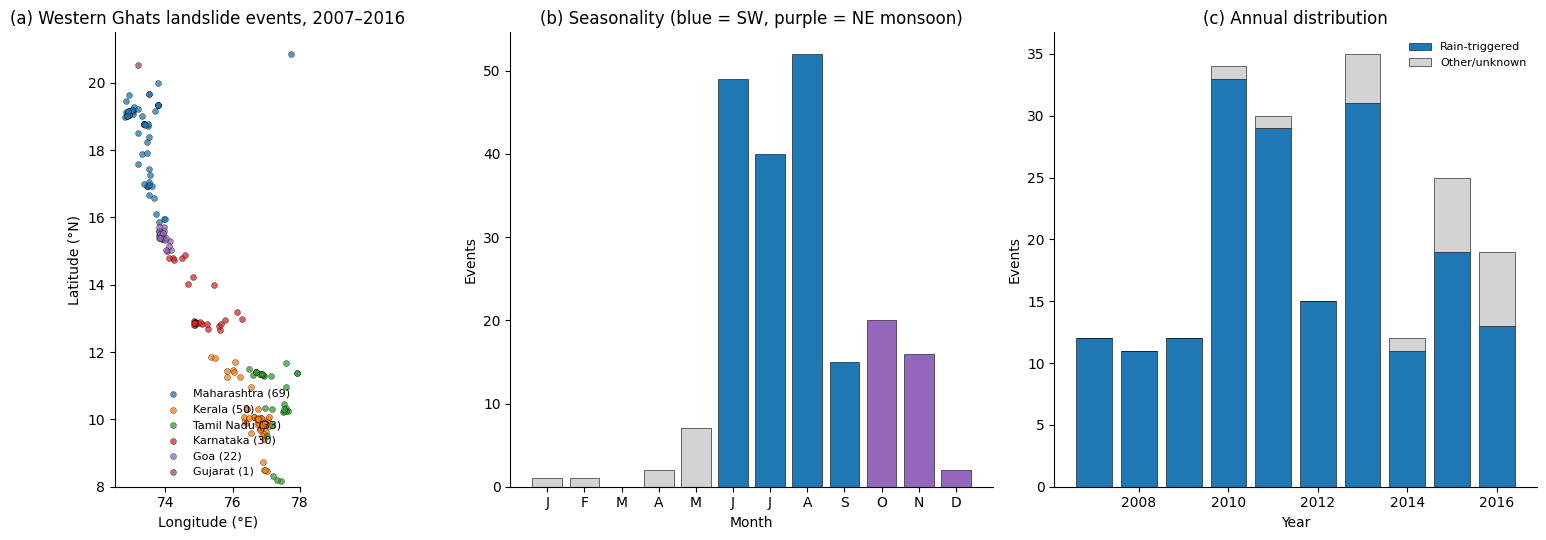

Rain-triggered share by season:
       count   mean
NE        38  0.895
Other     11  0.636
SW       156  0.929


In [18]:
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
fig = plt.figure(figsize=(16, 5.5))

ax0 = fig.add_subplot(1, 3, 1)
states = wg['admin'].value_counts().index.tolist()
cmap = plt.get_cmap('tab10')
for i, s in enumerate(states):
    d = wg[wg['admin'] == s]
    ax0.scatter(d['lon'], d['lat'], s=18, alpha=.75, color=cmap(i), label=f'{s} ({len(d)})',
                edgecolor='k', linewidth=.3)
ax0.set(xlim=(b['lon_min'], b['lon_max']), ylim=(b['lat_min'], b['lat_max']),
        xlabel='Longitude (°E)', ylabel='Latitude (°N)', title='(a) Western Ghats landslide events, 2007–2016')
ax0.set_aspect('equal'); ax0.legend(fontsize=8, loc='lower right', frameon=False)

ax1 = fig.add_subplot(1, 3, 2)
m = wg['month'].value_counts().reindex(range(1, 13), fill_value=0)
colors = ['tab:blue' if k in SW_MONSOON else ('tab:purple' if k in NE_MONSOON else 'lightgray') for k in m.index]
ax1.bar(m.index, m.values, color=colors, edgecolor='k', linewidth=.4)
ax1.set(xticks=range(1, 13), xticklabels=list('JFMAMJJASOND'), xlabel='Month', ylabel='Events',
        title='(b) Seasonality (blue = SW, purple = NE monsoon)')

ax2 = fig.add_subplot(1, 3, 3)
yr = wg.groupby(['year', 'rain_triggered']).size().unstack(fill_value=0)
yr = yr.reindex(columns=[True, False], fill_value=0)
ax2.bar(yr.index, yr[True], color='tab:blue', edgecolor='k', linewidth=.4, label='Rain-triggered')
ax2.bar(yr.index, yr[False], bottom=yr[True], color='lightgray', edgecolor='k', linewidth=.4, label='Other/unknown')
ax2.set(xlabel='Year', ylabel='Events', title='(c) Annual distribution')
ax2.legend(frameon=False, fontsize=8)

plt.tight_layout()
plt.savefig(f'{OUT}/fig2_wg_event_overview.png', dpi=300, bbox_inches='tight')
plt.savefig(f'{OUT}/fig2_wg_event_overview.pdf', bbox_inches='tight')
plt.show()

print('Rain-triggered share by season:')
print(wg.groupby(np.select([wg['sw_monsoon'], wg['ne_monsoon']], ['SW', 'NE'], 'Other'))['rain_triggered']
        .agg(['count', 'mean']).round(3).to_string())

Cell 5: Landslide4Sense structure and pairing check

"Cell 5 (corrected): Pairing check using the ID from the filename stem"

In [19]:
def num_id(p):
    stem = os.path.splitext(os.path.basename(p))[0]      # 'image_305'
    return int(stem.split('_')[-1])                       # 305

tr_img = sorted(glob.glob(f'{L4S_PATH}/TrainData/img/*.h5'), key=num_id)
tr_msk = sorted(glob.glob(f'{L4S_PATH}/TrainData/mask/*.h5'), key=num_id)
va_img = sorted(glob.glob(f'{L4S_PATH}/ValidData/img/*.h5'), key=num_id)
te_img = sorted(glob.glob(f'{L4S_PATH}/TestData/img/*.h5'), key=num_id)

for name, lst in [('train img', tr_img), ('train mask', tr_msk), ('valid img', va_img), ('test img', te_img)]:
    ids = [num_id(p) for p in lst]
    print(f'{name:10s}: n={len(ids)} | range {min(ids)}–{max(ids)} | '
          f'unique={len(set(ids))} | contiguous={set(ids) == set(range(min(ids), max(ids)+1))}')

ids_i, ids_m = {num_id(p) for p in tr_img}, {num_id(p) for p in tr_msk}
print(f'\nUnpaired train images: {len(ids_i - ids_m)} | unpaired masks: {len(ids_m - ids_i)}')

pairs_ok = all(num_id(a) == num_id(b) for a, b in zip(tr_img, tr_msk))
print('Sorted lists aligned one-to-one:', pairs_ok)
print('First 3 pairs:', [(os.path.basename(a), os.path.basename(b)) for a, b in zip(tr_img[:3], tr_msk[:3])])

train img : n=3799 | range 1–3799 | unique=3799 | contiguous=True
train mask: n=3799 | range 1–3799 | unique=3799 | contiguous=True
valid img : n=245 | range 1–245 | unique=245 | contiguous=True
test img  : n=800 | range 1–800 | unique=800 | contiguous=True

Unpaired train images: 0 | unpaired masks: 0
Sorted lists aligned one-to-one: True
First 3 pairs: [('image_1.h5', 'mask_1.h5'), ('image_2.h5', 'mask_2.h5'), ('image_3.h5', 'mask_3.h5')]


"Cell 6: Band statistics and class imbalance over the full training set"

In [20]:
from tqdm.auto import tqdm

BANDS = [f'B{i}' for i in range(1, 13)] + ['Slope', 'DEM']
s1 = np.zeros(14); s2 = np.zeros(14); cnt = np.zeros(14); nan_ct = np.zeros(14)
bmin = np.full(14, np.inf); bmax = np.full(14, -np.inf)
rows = []

for pi, pm in tqdm(zip(tr_img, tr_msk), total=len(tr_img)):
    _, im = read_h5(pi); _, m = read_h5(pm)
    flat = im.reshape(-1, 14)
    nan_mask = np.isnan(flat)
    nan_ct += nan_mask.sum(0)
    v = np.where(nan_mask, 0.0, flat)
    s1 += v.sum(0); s2 += (v ** 2).sum(0); cnt += (~nan_mask).sum(0)
    bmin = np.minimum(bmin, np.nanmin(flat, 0)); bmax = np.maximum(bmax, np.nanmax(flat, 0))
    pos = int((m > 0).sum())
    rows.append({'id': num_id(pi), 'pos_pixels': pos, 'pos_ratio': pos / m.size,
                 'has_nan': bool(nan_mask.any()),
                 'mean_slope': float(np.nanmean(im[..., 12])), 'mean_dem': float(np.nanmean(im[..., 13]))})

mean = s1 / cnt
std = np.sqrt(np.maximum(s2 / cnt - mean ** 2, 0))
stats = pd.DataFrame({'band': BANDS, 'mean': mean, 'std': std, 'min': bmin, 'max': bmax, 'nan_count': nan_ct.astype(int)})
patch = pd.DataFrame(rows)

print(stats.round(4).to_string(index=False))
tot_pix = len(patch) * 128 * 128
print(f"\nLandslide pixel ratio (train): {patch['pos_pixels'].sum() / tot_pix:.4%}")
print(f"Patches with >=1 landslide pixel: {(patch['pos_pixels'] > 0).sum()} / {len(patch)} "
      f"({(patch['pos_pixels'] > 0).mean():.1%})")
print(f"Patches containing NaNs: {patch['has_nan'].sum()}")
print('\nPer-patch landslide ratio quantiles (positive patches only):')
print(patch.loc[patch['pos_pixels'] > 0, 'pos_ratio'].quantile([.1, .25, .5, .75, .9, .99]).round(4).to_string())

stats.to_csv(f'{OUT}/l4s_band_stats.csv', index=False)
patch.to_csv(f'{OUT}/l4s_train_patch_index.csv', index=False)
json.dump({'bands': BANDS, 'mean': mean.tolist(), 'std': std.tolist()},
          open(f'{OUT}/l4s_norm.json', 'w'), indent=2)
print('\nSaved: l4s_band_stats.csv, l4s_train_patch_index.csv, l4s_norm.json')

  0%|          | 0/3799 [00:00<?, ?it/s]

 band   mean    std  min     max  nan_count
   B1 0.9257 0.1410  0.0  3.1057          0
   B2 0.9227 0.2207  0.0 19.7615          0
   B3 0.9541 0.3184  0.0 31.5518          0
   B4 0.9596 0.5724  0.0 33.1601          0
   B5 1.0228 0.4601  0.0  9.9728          0
   B6 1.0426 0.4465  0.0  4.1441          0
   B7 1.0358 0.4651  0.0  3.6925          0
   B8 1.0468 0.4948  0.0  8.3129          0
   B9 1.1699 0.5133  0.0  3.5486          0
  B10 1.1736 0.6836  0.0 21.4415          0
  B11 1.0495 0.5323  0.0  5.7864          0
  B12 1.0370 0.6628  0.0 19.6613          0
Slope 1.2511 0.6784  0.0  4.0409          0
  DEM 1.6495 1.0727  0.0  5.1214          0

Landslide pixel ratio (train): 2.3180%
Patches with >=1 landslide pixel: 2231 / 3799 (58.7%)
Patches containing NaNs: 0

Per-patch landslide ratio quantiles (positive patches only):
0.10    0.0020
0.25    0.0060
0.50    0.0204
0.75    0.0516
0.90    0.1030
0.99    0.2515

Saved: l4s_band_stats.csv, l4s_train_patch_index.csv, l4s_norm.jso

"Cell 7: Robust clipping thresholds, the zero-pixel check, and a visual sanity check"

  0%|          | 0/800 [00:00<?, ?it/s]

 band   p0.1  p99.9  raw_max  robust_mean  robust_std  raw_std  zero_px_frac
   B1 0.6791 1.8888   3.1057       0.9262      0.1429   0.1410        0.0002
   B2 0.6027 2.7418  19.7615       0.9234      0.2200   0.2207        0.0002
   B3 0.4522 3.3614  31.5518       0.9550      0.3178   0.3184        0.0002
   B4 0.3549 5.2699  33.1601       0.9625      0.5739   0.5724        0.0002
   B5 0.2230 3.5457   9.9728       1.0245      0.4646   0.4601        0.0002
   B6 0.1098 2.2226   4.1441       1.0435      0.4500   0.4465        0.0002
   B7 0.0801 2.2811   3.6925       1.0361      0.4682   0.4651        0.0002
   B8 0.0613 2.3669   8.3129       1.0472      0.4985   0.4948        0.0002
   B9 0.0653 2.6229   3.5486       1.1730      0.5233   0.5133        0.0002
  B10 0.3316 8.9524  21.4415       1.1555      0.6422   0.6836        0.0002
  B11 0.0206 3.2370   5.7864       1.0503      0.5363   0.5323        0.0002
  B12 0.0192 4.8105  19.6613       1.0388      0.6672   0.6628        0.0002

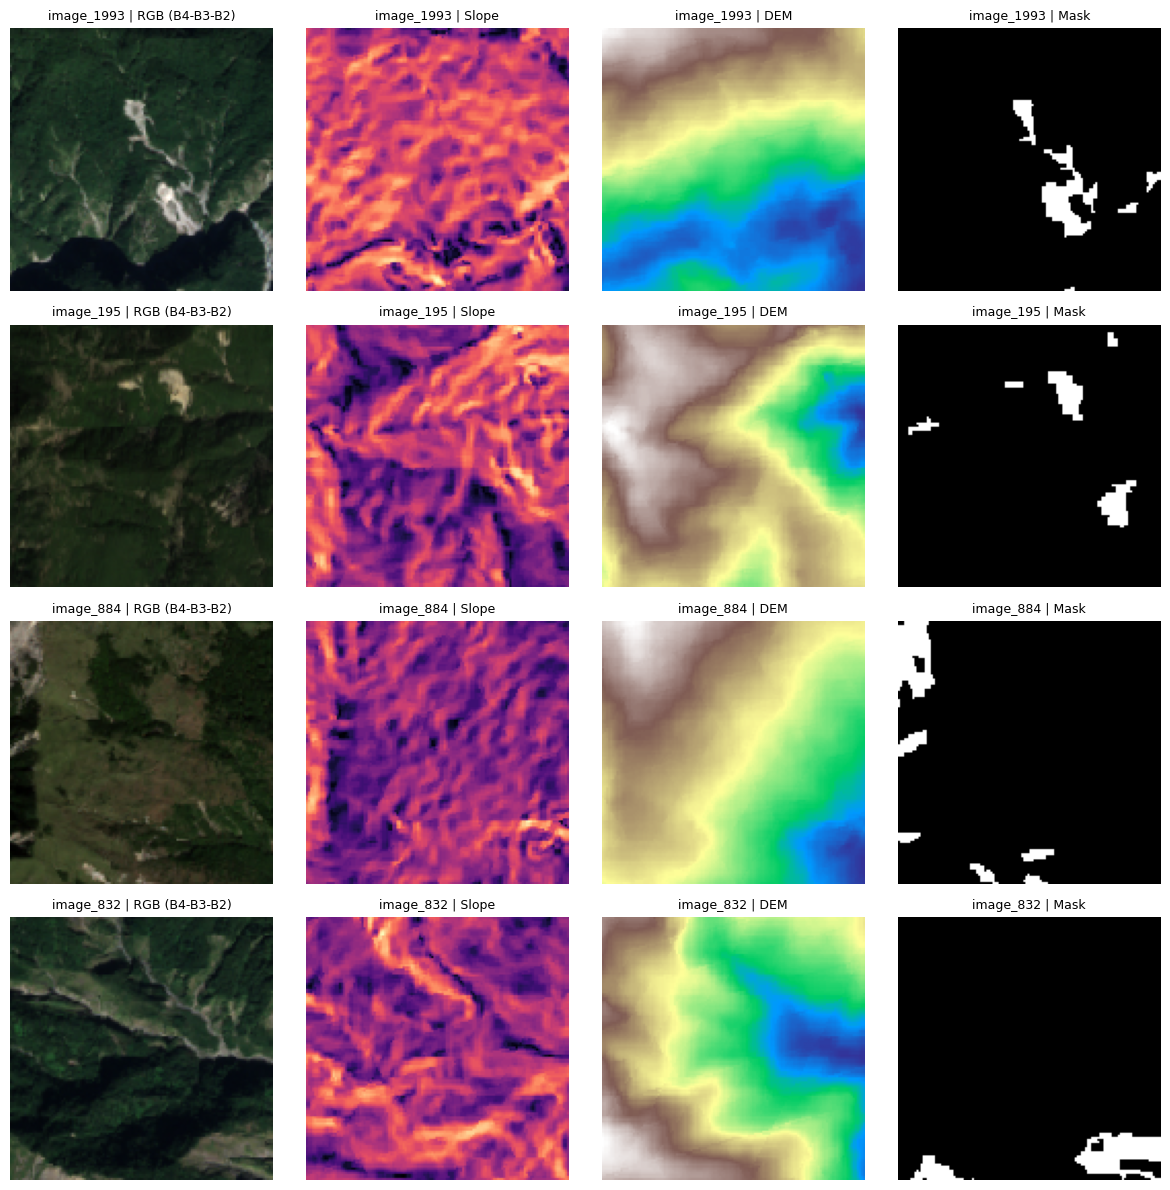

In [21]:
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(len(tr_img), size=800, replace=False)
PIX_PER_PATCH = 2000
buf, zero_frac = [], []

for i in tqdm(sample_ids):
    _, im = read_h5(tr_img[i])
    flat = im.reshape(-1, 14)
    zero_frac.append((flat == 0).all(axis=1).mean())
    buf.append(flat[rng.choice(flat.shape[0], PIX_PER_PATCH, replace=False)])
buf = np.concatenate(buf)

p_lo = np.percentile(buf, 0.1, axis=0); p_hi = np.percentile(buf, 99.9, axis=0)
clipped = np.clip(buf, p_lo, p_hi)
r_mean, r_std = clipped.mean(0), clipped.std(0)

robust = pd.DataFrame({'band': BANDS, 'p0.1': p_lo, 'p99.9': p_hi, 'raw_max': bmax,
                       'robust_mean': r_mean, 'robust_std': r_std, 'raw_std': std,
                       'zero_px_frac': (buf == 0).mean(0)})
print(robust.round(4).to_string(index=False))
zf = np.array(zero_frac)
print(f'\nPixels that are 0 in ALL 14 bands (likely no-data): mean {zf.mean():.4%} | '
      f'patches with any such pixel: {(zf > 0).mean():.1%}')

json.dump({'bands': BANDS, 'clip_lo': p_lo.tolist(), 'clip_hi': p_hi.tolist(),
           'mean': r_mean.tolist(), 'std': r_std.tolist()},
          open(f'{OUT}/l4s_norm_robust.json', 'w'), indent=2)

show = patch[patch['pos_ratio'].between(0.03, 0.15)].sample(4, random_state=SEED)['id'].tolist()
fig, ax = plt.subplots(4, 4, figsize=(12, 12))
for r, pid in enumerate(show):
    _, im = read_h5(tr_img[pid - 1]); _, m = read_h5(tr_msk[pid - 1])
    rgb = np.clip(im[..., [3, 2, 1]], p_lo[[3, 2, 1]], p_hi[[3, 2, 1]])
    rgb = (rgb - p_lo[[3, 2, 1]]) / (p_hi[[3, 2, 1]] - p_lo[[3, 2, 1]])
    for c, (img, t, cm) in enumerate([(rgb, 'RGB (B4-B3-B2)', None), (im[..., 12], 'Slope', 'magma'),
                                      (im[..., 13], 'DEM', 'terrain'), (m, 'Mask', 'gray')]):
        ax[r, c].imshow(img, cmap=cm); ax[r, c].axis('off')
        ax[r, c].set_title(f'image_{pid} | {t}', fontsize=9)
plt.tight_layout(); plt.savefig(f'{OUT}/fig_l4s_samples.png', dpi=200, bbox_inches='tight'); plt.show()

Cell 8: Inspect the Hugging Face repository before downloading

In [22]:
!pip -q install -U huggingface_hub
from huggingface_hub import list_repo_files

REPO = 'ibm-nasa-geospatial/Landslide4sense'
files = list_repo_files(REPO, repo_type='dataset')
print('Total files:', len(files))

tree = pd.Series(['/'.join(f.split('/')[:-1]) or '(root)' for f in files]).value_counts().sort_index()
print('\nFolder -> file count:\n', tree.to_string())

print('\nNon-.h5 files:', [f for f in files if not f.endswith('.h5')])
for folder in tree.index:
    ex = [f for f in files if f.startswith(folder + '/') and f.endswith('.h5')][:2]
    if ex: print(f'{folder}: e.g. {ex}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 828.5/828.5 kB 10.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.3/125.3 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 66.3 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.6/95.6 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.4/83.4 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.6/69.6 kB 2.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
datasets 5.0.0 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.0.0 which is incompatible.
diffusers 0.37.1 requires huggingface-hub<2.0,>=0.34.0, but you have huggingface-hub 2.0.0 which is incompatible.
tokenizers 0.22.2 requ

### Cell 9: Download the official validation and test splits, then verify them against Kaggle ###

In [23]:
from huggingface_hub import snapshot_download

HF_DIR = '/kaggle/working/l4s_official'
snapshot_download(repo_id=REPO, repo_type='dataset', local_dir=HF_DIR, max_workers=16,
                  allow_patterns=['images/validation/*', 'images/test/*',
                                  'annotations/validation/*', 'annotations/test/*'])

hf = {k: sorted(glob.glob(f'{HF_DIR}/{k}/*.h5'), key=num_id) for k in
      ['images/validation', 'images/test', 'annotations/validation', 'annotations/test']}
for k, v in hf.items():
    print(f'{k:24s}: {len(v)} files | ids {num_id(v[0])}–{num_id(v[-1])}')

train_ann_ids = sorted(num_id(f) for f in files if f.startswith('annotations/train/'))
extra = sorted(set(train_ann_ids) - set(range(1, 3800)))
dups = len(train_ann_ids) - len(set(train_ann_ids))
print(f'\nHF annotations/train: {len(train_ann_ids)} files | ids outside 1–3799: {extra} | duplicate ids: {dups}')

def compare(kaggle_list, hf_list, n=50):
    idx = np.random.default_rng(SEED).choice(len(kaggle_list), size=min(n, len(kaggle_list)), replace=False)
    same = 0
    for i in idx:
        _, a = read_h5(kaggle_list[i]); _, b = read_h5(hf_list[i])
        same += int(a.shape == b.shape and np.allclose(a, b, equal_nan=True))
    return same, len(idx)
for name, kl, hl in [('validation', va_img, hf['images/validation']), ('test', te_img, hf['images/test'])]:
    s, n = compare(kl, hl)
    print(f'Kaggle vs HF {name} images identical: {s}/{n}')

split_stats = []
for split in ['validation', 'test']:
    pos, tot, pos_p = 0, 0, 0
    for p in hf[f'annotations/{split}']:
        _, m = read_h5(p); k = int((m > 0).sum())
        pos += k; tot += m.size; pos_p += int(k > 0)
    n = len(hf[f'annotations/{split}'])
    split_stats.append({'split': split, 'patches': n, 'pixel_ratio_%': round(100 * pos / tot, 3),
                        'positive_patches_%': round(100 * pos_p / n, 1)})
split_stats.insert(0, {'split': 'train', 'patches': len(patch),
                       'pixel_ratio_%': round(100 * patch['pos_pixels'].sum() / (len(patch) * 16384), 3),
                       'positive_patches_%': round(100 * (patch['pos_pixels'] > 0).mean(), 1)})
split_df = pd.DataFrame(split_stats)
print('\n', split_df.to_string(index=False))
split_df.to_csv(f'{OUT}/l4s_split_stats.csv', index=False)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2090 files:   0%|          | 0/2090 [00:00<?, ?it/s]

images/validation       : 245 files | ids 1–245
images/test             : 800 files | ids 1–800
annotations/validation  : 245 files | ids 1–245
annotations/test        : 800 files | ids 1–800

HF annotations/train: 3804 files | ids outside 1–3799: [] | duplicate ids: 5
Kaggle vs HF validation images identical: 50/50
Kaggle vs HF test images identical: 50/50

      split  patches  pixel_ratio_%  positive_patches_%
     train     3799          2.318                58.7
validation      245          1.713                59.6
      test      800          1.889                67.0


### Cell 10: Stage 1a summary and cleanup ###

In [24]:
import shutil
shutil.rmtree(f'{HF_DIR}/images', ignore_errors=True)

L4S_SPLITS = {
    'train':      {'img': f'{L4S_PATH}/TrainData/img', 'mask': f'{L4S_PATH}/TrainData/mask', 'n': len(tr_img)},
    'validation': {'img': f'{L4S_PATH}/ValidData/img', 'mask': f'{HF_DIR}/annotations/validation', 'n': len(va_img)},
    'test':       {'img': f'{L4S_PATH}/TestData/img',  'mask': f'{HF_DIR}/annotations/test', 'n': len(te_img)},
}
json.dump(L4S_SPLITS, open(f'{OUT}/l4s_split_paths.json', 'w'), indent=2)

summary = {
    'catalog': {'glc_rows': int(len(glc)), 'nasa2016_rows': int(len(nasa)),
                'nasa2016_duplicate_rate': round(float(dup.mean()), 4),
                'merged_global': int(len(events)), 'india_events': int(in_india.sum()),
                'catalog_end_date': str(events['date'].max().date())},
    'western_ghats': {'events': int(len(wg)), 'rain_triggered': int(wg['rain_triggered'].sum()),
                      'sw_monsoon': int(wg['sw_monsoon'].sum()), 'ne_monsoon': int(wg['ne_monsoon'].sum()),
                      'taskC_candidates': int(len(taskC)), 'taskC_unique_event_days': int(taskC['date'].dt.normalize().nunique()),
                      'years': [int(wg['year'].min()), int(wg['year'].max())],
                      'flags_for_stage1b': ['Mumbai urban cluster', 'Mangaluru coastal cluster',
                                            'Amravati plateau point', 'Salem/Yercaud Eastern Ghats points']},
    'landslide4sense': {'split_stats': split_df.to_dict(orient='records'),
                        'no_data_pixel_frac': round(float(zf.mean()), 6),
                        'clip_percentiles': [0.1, 99.9], 'norm_file': 'l4s_norm_robust.json',
                        'val_test_masks_source': 'ibm-nasa-geospatial/Landslide4sense (HF)',
                        'kaggle_hf_image_match': '50/50 val, 50/50 test'},
}
json.dump(summary, open(f'{OUT}/stage1a_summary.json', 'w'), indent=2)
print(json.dumps(summary, indent=2))

print('\nOutputs:')
for root, _, fs in os.walk('/kaggle/working'):
    n = len(fs)
    if n and root.count(os.sep) <= 4:
        size = sum(os.path.getsize(os.path.join(root, f)) for f in fs) / 1e6
        print(f'  {root}: {n} files, {size:.1f} MB')

{
  "catalog": {
    "glc_rows": 11033,
    "nasa2016_rows": 1693,
    "nasa2016_duplicate_rate": 0.9923,
    "merged_global": 11046,
    "india_events": 1265,
    "catalog_end_date": "2017-09-28"
  },
  "western_ghats": {
    "events": 205,
    "rain_triggered": 186,
    "sw_monsoon": 156,
    "ne_monsoon": 38,
    "taskC_candidates": 161,
    "taskC_unique_event_days": 120,
    "years": [
      2007,
      2016
    ],
    "flags_for_stage1b": [
      "Mumbai urban cluster",
      "Mangaluru coastal cluster",
      "Amravati plateau point",
      "Salem/Yercaud Eastern Ghats points"
    ]
  },
  "landslide4sense": {
    "split_stats": [
      {
        "split": "train",
        "patches": 3799,
        "pixel_ratio_%": 2.318,
        "positive_patches_%": 58.7
      },
      {
        "split": "validation",
        "patches": 245,
        "pixel_ratio_%": 1.713,
        "positive_patches_%": 59.6
      },
      {
        "split": "test",
        "patches": 800,
        "pixel_ratio_%"

In [25]:
for s in ['validation', 'test']:
    p = f'{HF_DIR}/annotations/{s}'
    print(s, len(glob.glob(f'{p}/*.h5')), 'masks,', round(sum(os.path.getsize(f) for f in glob.glob(f'{p}/*.h5')) / 1e6, 1), 'MB')

validation 245 masks, 4.5 MB
test 800 masks, 14.7 MB


In [26]:
def read_h5(p):
    with h5py.File(p, 'r') as f:
        k = list(f.keys())[0]
        return k, f[k][()]

### Kerala 2018 inventory without downloading it manually ###

In [27]:
import os, json, requests, zipfile, io, glob
DOI = 'doi:10.17026/dans-x6c-y7x2'
HOST = 'https://phys-techsciences.datastations.nl'
KER_DIR = '/kaggle/working/kerala2018'
os.makedirs(KER_DIR, exist_ok=True)

meta = requests.get(f'{HOST}/api/datasets/:persistentId/', params={'persistentId': DOI}, timeout=60)
print('Metadata status:', meta.status_code)
files = meta.json()['data']['latestVersion']['files']
for f in files:
    df = f['dataFile']
    print(f"{df['id']:>9} | {df['filename']:45s} | {df.get('filesize', 0)/1e6:6.2f} MB | restricted={f.get('restricted')}")

for f in files:
    df = f['dataFile']
    r = requests.get(f"{HOST}/api/access/datafile/{df['id']}", timeout=300)
    print(f"{df['filename']}: HTTP {r.status_code}, {len(r.content)/1e6:.2f} MB")
    if r.status_code == 200:
        path = os.path.join(KER_DIR, df['filename'])
        open(path, 'wb').write(r.content)
        if path.endswith('.zip'):
            zipfile.ZipFile(path).extractall(KER_DIR)

print('\nFiles now in', KER_DIR)
for p in sorted(glob.glob(f'{KER_DIR}/**/*', recursive=True)):
    print('  ', os.path.relpath(p, KER_DIR))

Metadata status: 200
     6643 | easy-migration.zip                            |   0.02 MB | restricted=False
     6575 | Kerela landslide.cpg                          |   0.00 MB | restricted=False
     6579 | Kerela landslide.dbf                          |  13.81 MB | restricted=False
     6649 | Kerela landslide.mid                          |   0.66 MB | restricted=False
     6645 | Kerela landslide.mif                          |   0.25 MB | restricted=False
     6578 | Kerela landslide.prj                          |   0.00 MB | restricted=False
     6583 | Kerela landslide.sbn                          |   0.05 MB | restricted=False
     6580 | Kerela landslide.sbx                          |   0.00 MB | restricted=False
     6576 | Kerela landslide.shp                          |   0.21 MB | restricted=False
     6581 | Kerela landslide.shx                          |   0.04 MB | restricted=False
     6577 | Kerela landslide.xml                          |   0.00 MB | restricted=False


### Stage 1b, Cell 2: Load and audit the Kerala 2018 inventory ###

In [28]:
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt

ker = gpd.read_file(f'{KER_DIR}/Kerela landslide.shp')
print('Rows:', len(ker), '| expected 4728')
print('CRS:', ker.crs)
print('Geometry types:', ker.geom_type.value_counts().to_dict())
print('Empty/missing geometries:', int(ker.geometry.is_empty.sum() + ker.geometry.isna().sum()))
print('Bounds (native CRS):', np.round(ker.total_bounds, 4))

ker_wgs = ker.to_crs(4326) if ker.crs and ker.crs.to_epsg() != 4326 else ker
print('Bounds (WGS84 lon/lat):', np.round(ker_wgs.total_bounds, 4))

print('\nColumns and dtypes:')
print(ker.dtypes.to_string())

print('\nFirst 3 rows:')
print(ker.drop(columns='geometry').head(3).T.to_string())

print('\nLow-cardinality columns (<= 30 unique values):')
for c in ker.columns.drop('geometry'):
    nu = ker[c].nunique(dropna=False)
    if nu <= 30:
        print(f'\n--- {c} ({nu} unique) ---')
        print(ker[c].value_counts(dropna=False).to_string())

xy = np.column_stack([ker_wgs.geometry.x.round(6), ker_wgs.geometry.y.round(6)])
print('\nExact duplicate coordinates:', len(xy) - len(np.unique(xy, axis=0)))

Rows: 4728 | expected 4728
CRS: EPSG:4326
Geometry types: {'Point': 4728}
Empty/missing geometries: 0
Bounds (native CRS): [75.0154  8.4745 77.3963 12.655 ]
Bounds (WGS84 lon/lat): [75.0154  8.4745 77.3963 12.655 ]

Columns and dtypes:
No               int64
District        object
NRSC            object
GSI             object
New             object
Type_of_sl      object
Length           int64
Width            int64
Area           float64
Building_I       int64
Road_impac      object
Impact_Agr      object
LU_2010         object
LU_2018         object
Specific_r      object
Remarks         object
POINT_X        float64
POINT_Y        float64
Reclass_Sl       int64
RASTERVALU     float64
geometry      geometry

First 3 rows:
                                                                                                                                                     0          1          2
No                                                                                           

### 1b, Cell 3: Decode the metadata, save a clean inventory, and compare it with the NASA events ###

metadata.pdf: 3336 characters

Explanations to attributes of landslide inventory dataset in Kerala in 2018 Monsoon
District: the name of the district in Kerala where the landslide occurred. 
NRSC: data source. There are two values for this attribute, Y means landslide mapped by NRSC  
and N means it is not mapped by NRSC.
GSI: data source. There are two values for this attribute, Y means landslide mapped by GSI and N  
means it is not mapped by GSI.
New: data source. There are two values for this attribute, Y means landslide was newly mapped  
during this research by authors and N means it is not newly mapped by authors.
Type_of_sl: landslide types. There are three values for this attribute, DF means debris flow, SS  
means surficial slide and RF means rock fall.
Length: the maximum length of a landslide mapped by GSI or authors, which is measured using  
measure tool supplied by Google Earth.
Width: the maximum width of a landslide mapped by GSI or authors, which is measured using  
m

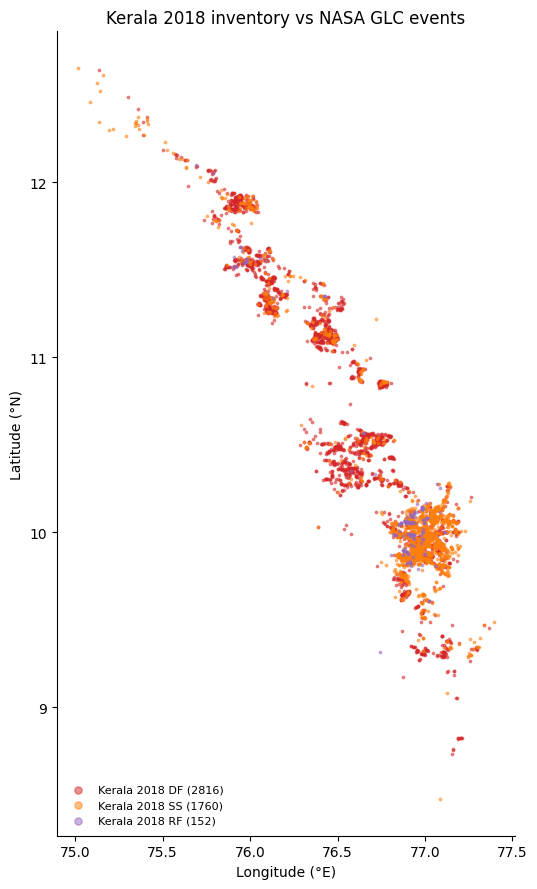

In [29]:
!pip -q install pypdf
from pypdf import PdfReader
import glob, os, re

text = '\n'.join(page.extract_text() or '' for page in PdfReader(f'{KER_DIR}/metadata.pdf').pages)
open(f'{KER_DIR}/metadata.txt', 'w').write(text)
print(f'metadata.pdf: {len(text)} characters\n')
print(text[:6000])

keep = ['No', 'District', 'NRSC', 'GSI', 'New', 'Type_of_sl', 'Area', 'Building_I', 'Road_impac',
        'LU_2010', 'LU_2018', 'Specific_r', 'RASTERVALU', 'Reclass_Sl', 'geometry']
ker_clean = ker[keep].rename(columns={'Type_of_sl': 'ls_type', 'Building_I': 'bldg_impact',
                                      'Road_impac': 'road_impact', 'Specific_r': 'specific_reason',
                                      'RASTERVALU': 'slope_src_deg', 'Reclass_Sl': 'slope_src_class'})
ker_clean['lon'], ker_clean['lat'] = ker_clean.geometry.x, ker_clean.geometry.y
ker_clean['event_date'] = '2018-08-15'
ker_clean.to_file('/kaggle/working/kerala2018_inventory_clean.gpkg', driver='GPKG')
print('\nSaved kerala2018_inventory_clean.gpkg:', ker_clean.shape)

hits = glob.glob('/kaggle/input/**/wg_events_all.csv', recursive=True)
print('\nNASA WG file:', hits)
fig, ax = plt.subplots(figsize=(7, 9))
colors = {'DF': 'tab:red', 'SS': 'tab:orange', 'RF': 'tab:purple'}
for t, c in colors.items():
    d = ker_clean[ker_clean['ls_type'] == t]
    ax.scatter(d['lon'], d['lat'], s=3, alpha=.5, c=c, label=f'Kerala 2018 {t} ({len(d)})')
if hits:
    wgev = pd.read_csv(hits[0])
    kv = wgev[wgev['lon'].between(74.8, 77.5) & wgev['lat'].between(8.2, 12.9)]
    ax.scatter(kv['lon'], kv['lat'], s=40, marker='^', facecolor='none', edgecolor='k',
               linewidth=1, label=f'NASA GLC 2007–2016 ({len(kv)})')
ax.set(xlabel='Longitude (°E)', ylabel='Latitude (°N)', title='Kerala 2018 inventory vs NASA GLC events')
ax.set_aspect('equal'); ax.legend(markerscale=3, fontsize=8, loc='lower left', frameon=False)
plt.tight_layout(); plt.savefig('/kaggle/working/fig_kerala_vs_glc.png', dpi=250, bbox_inches='tight'); plt.show()

### 1b, Cell 4: Add cause flags and save the final inventory ###

In [30]:
def has_code(s, codes):
    if s is None or pd.isna(s) or str(s).strip().lower() == 'none':
        return False
    return any(int(c) in codes for c in str(s).split('/') if c.strip().isdigit())

ker_clean['anthropogenic'] = ker_clean['specific_reason'].apply(lambda s: has_code(s, {1, 2, 3}))
ker_clean['reactivation']  = ker_clean['specific_reason'].apply(lambda s: has_code(s, {4}))
ker_clean['river_undercut'] = ker_clean['specific_reason'].apply(lambda s: has_code(s, {5, 6}))
ker_clean['landuse_change'] = ker_clean['specific_reason'].apply(lambda s: has_code(s, {7, 8, 9, 10}))
ker_clean['lu_built_2018'] = ker_clean['LU_2018'].isin(['BUI', 'ROA', 'CSB', 'CSV', 'QUU'])
ker_clean['natural'] = ~(ker_clean['anthropogenic'] | ker_clean['lu_built_2018'])

flags = ['anthropogenic', 'reactivation', 'river_undercut', 'landuse_change', 'lu_built_2018', 'natural']
print(ker_clean[flags].sum().to_string())
print('\nNatural share by landslide type:')
print(ker_clean.groupby('ls_type')['natural'].agg(['count', 'mean']).round(3).to_string())
print('\nNatural share by district:')
print(ker_clean.groupby('District')['natural'].agg(['count', 'mean']).sort_values('count', ascending=False).round(3).to_string())

ker_clean.to_file('/kaggle/working/kerala2018_inventory_clean.gpkg', driver='GPKG')
ker_clean.drop(columns='geometry').to_csv('/kaggle/working/kerala2018_inventory_clean.csv', index=False)
print('\nSaved inventory with flags:', ker_clean.shape)

anthropogenic      608
reactivation        46
river_undercut      76
landuse_change     160
lu_built_2018      435
natural           3857

Natural share by landslide type:
         count   mean
ls_type              
DF        2816  0.880
RF         152  0.961
SS        1760  0.701

Natural share by district:
                    count   mean
District                        
Idukki               2223  0.730
Palakkad              793  0.962
Malappuram            429  0.963
Wayanad               331  0.725
Thrissur              256  0.879
Kozhikode             228  0.860
Kannur                141  0.993
Ernakulam             107  0.860
Pathanamthitta        106  0.792
Kottayam               76  0.605
Kasaragod              24  0.917
Kollam                 10  1.000
Thiruvananthapuram      4  0.750

Saved inventory with flags: (4728, 24)


### 1b, Cell 5: Download the Copernicus 30 m DEM tiles for Kerala ###

In [31]:
!pip -q install rasterio
import math, requests, rasterio
from rasterio.merge import merge
from concurrent.futures import ThreadPoolExecutor

DEM_DIR = '/kaggle/working/dem_tiles'
os.makedirs(DEM_DIR, exist_ok=True)
AOI = dict(lon_min=74.8, lon_max=77.6, lat_min=8.2, lat_max=12.9)

def tile_name(lat, lon):
    ns, ew = ('N' if lat >= 0 else 'S'), ('E' if lon >= 0 else 'W')
    return f'Copernicus_DSM_COG_10_{ns}{abs(lat):02d}_00_{ew}{abs(lon):03d}_00_DEM'

tiles = [tile_name(la, lo)
         for la in range(math.floor(AOI['lat_min']), math.floor(AOI['lat_max']) + 1)
         for lo in range(math.floor(AOI['lon_min']), math.floor(AOI['lon_max']) + 1)]

def fetch(t):
    out = f'{DEM_DIR}/{t}.tif'
    if os.path.exists(out):
        return t, 'cached', os.path.getsize(out)
    r = requests.get(f'https://copernicus-dem-30m.s3.amazonaws.com/{t}/{t}.tif', timeout=300)
    if r.status_code == 200:
        open(out, 'wb').write(r.content)
        return t, 'ok', len(r.content)
    return t, f'missing (HTTP {r.status_code}, likely sea)', 0

with ThreadPoolExecutor(8) as ex:
    results = list(ex.map(fetch, tiles))
for t, status, size in results:
    print(f'{t}: {status} {size/1e6:.1f} MB')

paths = sorted(glob.glob(f'{DEM_DIR}/*.tif'))
print(f'\nTiles downloaded: {len(paths)} / {len(tiles)}')

srcs = [rasterio.open(p) for p in paths]
print('Tile CRS:', srcs[0].crs, '| resolution (deg):', srcs[0].res, '| nodata:', srcs[0].nodata)
mosaic, transform = merge(srcs, bounds=(AOI['lon_min'], AOI['lat_min'], AOI['lon_max'], AOI['lat_max']))
profile = srcs[0].profile.copy()
profile.update(height=mosaic.shape[1], width=mosaic.shape[2], transform=transform,
               driver='GTiff', compress='deflate', tiled=True, blockxsize=512, blockysize=512, BIGTIFF='IF_SAFER')
for s in srcs: s.close()

DEM_PATH = '/kaggle/working/dem_kerala_glo30_wgs84.tif'
with rasterio.open(DEM_PATH, 'w', **profile) as dst:
    dst.write(mosaic)

z = mosaic[0].astype('float32')
valid = z[np.isfinite(z) & (z > -100)]
print(f'\nMosaic: {mosaic.shape[1]} x {mosaic.shape[2]} pixels | {os.path.getsize(DEM_PATH)/1e6:.0f} MB on disk')
print(f'Elevation (m): min {valid.min():.0f} | median {np.median(valid):.0f} | max {valid.max():.0f}')
print(f'Share of pixels at <= 0 m (sea/coast): {(z <= 0).mean():.1%}')

Copernicus_DSM_COG_10_N08_00_E074_00_DEM: missing (HTTP 404, likely sea) 0.0 MB
Copernicus_DSM_COG_10_N08_00_E075_00_DEM: missing (HTTP 404, likely sea) 0.0 MB
Copernicus_DSM_COG_10_N08_00_E076_00_DEM: ok 8.5 MB
Copernicus_DSM_COG_10_N08_00_E077_00_DEM: ok 38.1 MB
Copernicus_DSM_COG_10_N09_00_E074_00_DEM: missing (HTTP 404, likely sea) 0.0 MB
Copernicus_DSM_COG_10_N09_00_E075_00_DEM: missing (HTTP 404, likely sea) 0.0 MB
Copernicus_DSM_COG_10_N09_00_E076_00_DEM: ok 34.3 MB
Copernicus_DSM_COG_10_N09_00_E077_00_DEM: ok 43.9 MB
Copernicus_DSM_COG_10_N10_00_E074_00_DEM: missing (HTTP 404, likely sea) 0.0 MB
Copernicus_DSM_COG_10_N10_00_E075_00_DEM: ok 1.9 MB
Copernicus_DSM_COG_10_N10_00_E076_00_DEM: ok 45.9 MB
Copernicus_DSM_COG_10_N10_00_E077_00_DEM: ok 42.8 MB
Copernicus_DSM_COG_10_N11_00_E074_00_DEM: missing (HTTP 404, likely sea) 0.0 MB
Copernicus_DSM_COG_10_N11_00_E075_00_DEM: ok 20.0 MB
Copernicus_DSM_COG_10_N11_00_E076_00_DEM: ok 44.2 MB
Copernicus_DSM_COG_10_N11_00_E077_00_DEM: ok 

### 1b, Cell 6: Re-merge with no-data and reproject to UTM zone 43N at 30 m ###

In [32]:
from rasterio.warp import calculate_default_transform, reproject, Resampling

NODATA_SRC = -32768.0
srcs = [rasterio.open(p) for p in paths]
bounds = (AOI['lon_min'], AOI['lat_min'], AOI['lon_max'], AOI['lat_max'])
mosaic, m_transform = merge(srcs, bounds=bounds, nodata=NODATA_SRC)
for s in srcs: s.close()
src = mosaic[0].astype('float32')
print(f'WGS84 mosaic: {src.shape} | no-data (missing sea tiles): {(src == NODATA_SRC).mean():.1%}')

DST_CRS, RES = 'EPSG:32643', 30.0
dst_transform, dst_w, dst_h = calculate_default_transform(
    'EPSG:4326', DST_CRS, src.shape[1], src.shape[0], *bounds, resolution=RES)
dem = np.full((dst_h, dst_w), np.nan, dtype='float32')
reproject(source=src, destination=dem,
          src_transform=m_transform, src_crs='EPSG:4326', src_nodata=NODATA_SRC,
          dst_transform=dst_transform, dst_crs=DST_CRS, dst_nodata=np.nan,
          resampling=Resampling.bilinear, num_threads=4)
del src, mosaic

DEM_UTM_PATH = '/kaggle/working/dem_kerala_glo30_utm43n_30m.tif'
utm_profile = dict(driver='GTiff', height=dst_h, width=dst_w, count=1, dtype='float32',
                   crs=DST_CRS, transform=dst_transform, nodata=np.nan,
                   compress='deflate', predictor=3, tiled=True, blockxsize=512, blockysize=512, BIGTIFF='IF_SAFER')
with rasterio.open(DEM_UTM_PATH, 'w', **utm_profile) as dst:
    dst.write(dem, 1)

land = np.isfinite(dem) & (dem > 0.5)
print(f'UTM grid: {dst_h} x {dst_w} pixels at {RES:.0f} m | {os.path.getsize(DEM_UTM_PATH)/1e6:.0f} MB')
print(f'No-data (outside tiles): {np.isnan(dem).mean():.1%} | land (> 0.5 m): {land.mean():.1%}')
print(f'Land elevation (m): median {np.median(dem[land]):.0f} | p90 {np.percentile(dem[land], 90):.0f} | max {dem[land].max():.0f}')

import shutil
shutil.rmtree(DEM_DIR, ignore_errors=True)
os.remove(DEM_PATH)
print('Removed raw tiles and WGS84 mosaic to free disk space')

WGS84 mosaic: (16920, 10080) | no-data (missing sea tiles): 19.5%
UTM grid: 17370 x 10284 pixels at 30 m | 270 MB
No-data (outside tiles): 20.3% | land (> 0.5 m): 57.7%
Land elevation (m): median 432 | p90 1003 | max 2680
Removed raw tiles and WGS84 mosaic to free disk space


### 1b, Cell 7: Terrain derivatives, plus a slope check against the inventory's ASTER values ###

In [33]:
from scipy import ndimage
from scipy.stats import pearsonr, spearmanr
from pyproj import Transformer
from tqdm.auto import tqdm

L = RES
nod = np.isnan(dem)
z_full = np.nan_to_num(dem, nan=0.0).astype('float32')
H, W = z_full.shape
out = {k: np.full((H, W), np.nan, 'float32') for k in ['slope', 'northness', 'eastness', 'prof_curv', 'plan_curv']}

CH = 3000
for r0 in tqdm(range(0, H, CH), desc='Derivatives'):
    r1 = min(r0 + CH, H)
    a0, a1 = max(r0 - 1, 0), min(r1 + 1, H)
    blk = np.pad(z_full[a0:a1], ((1 if r0 == 0 else 0, 1 if r1 == H else 0), (1, 1)), mode='edge')
    z1, z2, z3 = blk[:-2, :-2], blk[:-2, 1:-1], blk[:-2, 2:]
    z4, z5, z6 = blk[1:-1, :-2], blk[1:-1, 1:-1], blk[1:-1, 2:]
    z7, z8, z9 = blk[2:, :-2], blk[2:, 1:-1], blk[2:, 2:]

    dzdx = ((z3 + 2*z6 + z9) - (z1 + 2*z4 + z7)) / (8*L)
    dzdy = ((z7 + 2*z8 + z9) - (z1 + 2*z2 + z3)) / (8*L)
    grad = np.sqrt(dzdx**2 + dzdy**2)
    out['slope'][r0:r1] = np.degrees(np.arctan(grad))
    with np.errstate(invalid='ignore', divide='ignore'):
        out['eastness'][r0:r1]  = np.where(grad > 0, -dzdx / grad, 0)
        out['northness'][r0:r1] = np.where(grad > 0,  dzdy / grad, 0)

    D = ((z4 + z6) / 2 - z5) / L**2
    E = ((z2 + z8) / 2 - z5) / L**2
    F = (-z1 + z3 + z7 - z9) / (4 * L**2)
    G = (z6 - z4) / (2 * L)
    Hn = (z2 - z8) / (2 * L)
    gh = G**2 + Hn**2
    with np.errstate(invalid='ignore', divide='ignore'):
        out['prof_curv'][r0:r1] = 100 * np.where(gh > 0, -2 * (D*G**2 + E*Hn**2 + F*G*Hn) / gh, 0)
        out['plan_curv'][r0:r1] = 100 * np.where(gh > 0,  2 * (D*Hn**2 + E*G**2 - F*G*Hn) / gh, 0)

out['relief_330m'] = (ndimage.maximum_filter(z_full, size=11) - ndimage.minimum_filter(z_full, size=11)).astype('float32')
for k in out:
    out[k][nod] = np.nan
del z_full

BANDS_T = ['elev', 'slope', 'northness', 'eastness', 'prof_curv', 'plan_curv', 'relief_330m']
TERRAIN_PATH = '/kaggle/working/terrain_stack_utm43n_30m.tif'
prof = dict(utm_profile, count=len(BANDS_T))
with rasterio.open(TERRAIN_PATH, 'w', **prof) as dst:
    for i, k in enumerate(BANDS_T, 1):
        dst.write(dem if k == 'elev' else out[k], i)
        dst.set_band_description(i, k)
print(f'Saved terrain stack: {len(BANDS_T)} bands | {os.path.getsize(TERRAIN_PATH)/1e6:.0f} MB')

tr = Transformer.from_crs(4326, 32643, always_xy=True)
xs, ys = tr.transform(ker_clean['lon'].values, ker_clean['lat'].values)
rows, cols = map(np.array, rasterio.transform.rowcol(dst_transform, xs, ys))
ok = (rows >= 0) & (rows < H) & (cols >= 0) & (cols < W)
ls_slope = out['slope'][rows[ok], cols[ok]]
aster = ker_clean['slope_src_deg'].values[ok]
v = np.isfinite(ls_slope) & np.isfinite(aster)
print(f'\nInventory points on grid: {ok.sum()} / {len(ker_clean)}')
print(f'Slope GLO-30 vs ASTER (n={v.sum()}): Pearson r={pearsonr(ls_slope[v], aster[v])[0]:.3f} | '
      f'Spearman rho={spearmanr(ls_slope[v], aster[v])[0]:.3f} | '
      f'median |diff|={np.median(np.abs(ls_slope[v] - aster[v])):.1f}° | mean bias={np.mean(ls_slope[v] - aster[v]):+.1f}°')

rng = np.random.default_rng(42)
rr, cc = rng.integers(0, H, 400_000), rng.integers(0, W, 400_000)
lm = np.isfinite(dem[rr, cc]) & (dem[rr, cc] > 0.5)
bg = {k: out[k][rr[lm], cc[lm]] for k in ['slope', 'relief_330m', 'prof_curv', 'plan_curv']}
bg['elev'] = dem[rr[lm], cc[lm]]
lsv = {k: (dem if k == 'elev' else out[k])[rows[ok], cols[ok]] for k in bg}
cmp = pd.DataFrame({'landslides_median': {k: np.nanmedian(lsv[k]) for k in bg},
                    'random_land_median': {k: np.nanmedian(bg[k]) for k in bg}}).round(2)
print('\nLandslide points vs random land pixels (whole AOI, preliminary):')
print(cmp.to_string())

Derivatives:   0%|          | 0/6 [00:00<?, ?it/s]

Saved terrain stack: 7 bands | 5979 MB

Inventory points on grid: 4728 / 4728
Slope GLO-30 vs ASTER (n=4728): Pearson r=0.705 | Spearman rho=0.693 | median |diff|=4.8° | mean bias=+2.5°

Landslide points vs random land pixels (whole AOI, preliminary):
             landslides_median  random_land_median
slope                27.980000            4.900000
relief_330m         148.360001           27.840000
prof_curv            -0.030000           -0.010000
plan_curv             0.010000           -0.010000
elev                748.659973          432.299988


### 1b, Cell 8: Kerala boundary, then a compact, masked terrain stack ###

In [34]:
from rasterio.features import geometry_mask
from rasterio.windows import from_bounds, Window
import io

meta = requests.get('https://www.geoboundaries.org/api/current/gbOpen/IND/ADM1/', timeout=60).json()
adm1 = gpd.read_file(io.BytesIO(requests.get(meta['gjDownloadURL'], timeout=300).content))
print('States in file:', len(adm1), '| boundary year:', meta.get('boundaryYearRepresented'), '| source:', meta.get('boundarySource'))
kerala = adm1[adm1['shapeName'].str.strip().str.lower() == 'kerala'].to_crs(32643)
assert len(kerala) == 1, adm1['shapeName'].tolist()
ker_poly = kerala.geometry.union_all()
ker_buf = ker_poly.buffer(2000)
kerala.to_crs(4326).to_file('/kaggle/working/kerala_boundary_geoboundaries.gpkg', driver='GPKG')

pts_utm = gpd.GeoSeries(gpd.points_from_xy(xs, ys), crs=32643)
print(f'Inventory points inside Kerala: {pts_utm.within(ker_poly).sum()} | inside Kerala+2km: {pts_utm.within(ker_buf).sum()} / {len(pts_utm)}')

w0 = from_bounds(*ker_buf.bounds, transform=dst_transform)
win = Window(int(np.floor(w0.col_off)), int(np.floor(w0.row_off)),
             int(np.ceil(w0.width)) + 1, int(np.ceil(w0.height)) + 1).intersection(Window(0, 0, W, H))
r0, c0, h, w = int(win.row_off), int(win.col_off), int(win.height), int(win.width)
win_tf = rasterio.windows.transform(win, dst_transform)
in_buf = ~geometry_mask([ker_buf], out_shape=(h, w), transform=win_tf)
in_ker = ~geometry_mask([ker_poly], out_shape=(h, w), transform=win_tf)

SCALE = {'elev': 1, 'slope': 100, 'northness': 10000, 'eastness': 10000,
         'prof_curv': 100, 'plan_curv': 100, 'relief_330m': 10}
ND = -32768
dem_w = dem[r0:r0+h, c0:c0+w]
in_ker_land = in_ker & np.isfinite(dem_w) & (dem_w > 0.5)

COMPACT_PATH = '/kaggle/working/terrain_kerala_utm43n_30m_int16.tif'
cprof = dict(driver='GTiff', height=h, width=w, count=len(SCALE) + 1, dtype='int16', crs=DST_CRS,
             transform=win_tf, nodata=ND, compress='deflate', predictor=2, tiled=True,
             blockxsize=512, blockysize=512)
with rasterio.open(COMPACT_PATH, 'w', **cprof) as dst:
    for i, (k, s) in enumerate(SCALE.items(), 1):
        a = (dem_w if k == 'elev' else out[k][r0:r0+h, c0:c0+w]) * s
        bad = ~in_buf | ~np.isfinite(a)
        a = np.clip(np.nan_to_num(a, nan=0), -32767, 32767).astype('int16')
        a[bad] = ND
        dst.write(a, i); dst.set_band_description(i, f'{k} (x{s})')
    m = np.where(in_buf, in_ker_land.astype('int16'), ND).astype('int16')
    dst.write(m, len(SCALE) + 1); dst.set_band_description(len(SCALE) + 1, 'in_kerala_land (0/1)')

json.dump({'bands': list(SCALE) + ['in_kerala_land'], 'scale': SCALE, 'nodata': ND, 'crs': DST_CRS, 'res_m': RES},
          open('/kaggle/working/terrain_kerala_scale.json', 'w'), indent=2)
print(f'Compact stack: {h} x {w} px | {len(SCALE)+1} bands | {os.path.getsize(COMPACT_PATH)/1e6:.0f} MB')
print(f'Kerala land area from mask: {in_ker_land.sum() * RES**2 / 1e6:,.0f} km² (official state area ≈ 38,863 km²)')

os.remove(TERRAIN_PATH)
print('Removed 6 GB float32 stack')

States in file: 36 | boundary year: 2011 | source: DataMeet India community, Election Commission of India
Inventory points inside Kerala: 4719 | inside Kerala+2km: 4728 / 4728
Compact stack: 16711 x 9442 px | 8 bands | 911 MB
Kerala land area from mask: 37,889 km² (official state area ≈ 38,863 km²)
Removed 6 GB float32 stack


### 1b, Cell 9: Pre-event 2017 land cover onto the terrain grid ###

In [35]:
!pip -q install pystac-client planetary-computer
import pystac_client, planetary_computer

catalog = pystac_client.Client.open('https://planetarycomputer.microsoft.com/api/stac/v1',
                                    modifier=planetary_computer.sign_inplace)
bbox_ll = gpd.GeoSeries([ker_buf], crs=32643).to_crs(4326).total_bounds.tolist()
items = list(catalog.search(collections=['io-lulc-annual-v02'], bbox=bbox_ll,
                            datetime='2017-01-01/2017-12-31').items())
print(f'2017 tiles found: {len(items)} | e.g. {items[0].id} | '
      f"{items[0].properties.get('start_datetime')} -> {items[0].properties.get('end_datetime')}")

LC_NAMES = {1: 'Water', 2: 'Trees', 4: 'Flooded veg', 5: 'Crops', 7: 'Built', 8: 'Bare', 9: 'Snow/ice', 10: 'Clouds', 11: 'Rangeland'}
lc = np.zeros((h, w), dtype='uint8')
with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR', GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
    for it in tqdm(items, desc='LULC 2017 tiles'):
        with rasterio.open(it.assets['data'].href) as src:
            tmp = np.zeros((h, w), dtype='uint8')
            reproject(source=rasterio.band(src, 1), destination=tmp,
                      src_nodata=0, dst_transform=win_tf, dst_crs=DST_CRS, dst_nodata=0,
                      resampling=Resampling.mode, num_threads=4)
        lc = np.where(tmp > 0, tmp, lc)
        del tmp

LC_PATH = '/kaggle/working/lulc2017_io_kerala_utm43n_30m.tif'
with rasterio.open(LC_PATH, 'w', driver='GTiff', height=h, width=w, count=1, dtype='uint8', crs=DST_CRS,
                   transform=win_tf, nodata=0, compress='deflate', tiled=True, blockxsize=512, blockysize=512) as dst:
    dst.write(lc, 1); dst.set_band_description(1, 'IO LULC 2017 (9-class)')
print(f'Saved {LC_PATH} | {os.path.getsize(LC_PATH)/1e6:.0f} MB | uncovered pixels in Kerala land: {(lc[in_ker_land] == 0).mean():.2%}')

kr, kc = rows - r0, cols - c0
ls_lc = pd.Series(lc[kr, kc]).map(LC_NAMES).fillna('No data')
rng = np.random.default_rng(42)
rr, cc = rng.integers(0, h, 600_000), rng.integers(0, w, 600_000)
keep = in_ker_land[rr, cc]
bg_lc = pd.Series(lc[rr[keep], cc[keep]]).map(LC_NAMES).fillna('No data')
tab = pd.DataFrame({'kerala_land_%': (bg_lc.value_counts(normalize=True) * 100).round(1),
                    'landslides_%': (ls_lc.value_counts(normalize=True) * 100).round(1)}).fillna(0)
tab['ratio'] = (tab['landslides_%'] / tab['kerala_land_%'].replace(0, np.nan)).round(2)
print('\nPre-event (2017) land cover: Kerala land vs 2018 landslide points')
print(tab.sort_values('kerala_land_%', ascending=False).to_string())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 3.6 MB/s eta 0:00:00
2017 tiles found: 1 | e.g. 43P-2017 | 2017-01-01T00:00:00Z -> 2018-01-01T00:00:00Z


LULC 2017 tiles:   0%|          | 0/1 [00:00<?, ?it/s]

Saved /kaggle/working/lulc2017_io_kerala_utm43n_30m.tif | 5 MB | uncovered pixels in Kerala land: 0.00%

Pre-event (2017) land cover: Kerala land vs 2018 landslide points
             kerala_land_%  landslides_%  ratio
Trees                 65.0          84.7   1.30
Built                 21.6           3.2   0.15
Rangeland              7.2          12.0   1.67
Crops                  4.5           0.1   0.02
Water                  1.5           0.0   0.00
Flooded veg            0.3           0.0   0.00
Clouds                 0.0           0.0    NaN
Bare                   0.0           0.0    NaN


### 1b, Cell 10: Hydrological terrain features (wetness index, stream power, distance to streams) ###

In [36]:
!pip -q install whitebox
import whitebox, time
wbt = whitebox.WhiteboxTools()
wbt.set_verbose_mode(False)
HYD = '/kaggle/working/hydro'
os.makedirs(HYD, exist_ok=True)
wbt.set_working_dir(HYD)

d = np.where(np.isfinite(dem_w) & (dem_w > 0), dem_w, -9999).astype('float32')
with rasterio.open(f'{HYD}/dem.tif', 'w', driver='GTiff', height=h, width=w, count=1, dtype='float32',
                   crs=DST_CRS, transform=win_tf, nodata=-9999, compress='deflate', tiled=True, BIGTIFF='IF_SAFER') as dst:
    dst.write(d, 1)
del d

steps = [
    ('breach depressions', lambda: wbt.breach_depressions(dem='dem.tif', output='dem_br.tif', fill_pits=True)),
    ('slope (deg)',        lambda: wbt.slope(dem='dem_br.tif', output='slope_br.tif', units='degrees')),
    ('D-inf SCA',          lambda: wbt.d_inf_flow_accumulation(i='dem_br.tif', output='sca.tif', out_type='Specific Contributing Area')),
    ('TWI',                lambda: wbt.wetness_index(sca='sca.tif', slope='slope_br.tif', output='twi.tif')),
    ('SPI',                lambda: wbt.stream_power_index(sca='sca.tif', slope='slope_br.tif', output='spi.tif')),
    ('D8 accumulation',    lambda: wbt.d8_flow_accumulation(i='dem_br.tif', output='d8acc.tif', out_type='cells')),
    ('streams (1 km2)',    lambda: wbt.extract_streams(flow_accum='d8acc.tif', output='streams.tif', threshold=1111, zero_background=True)),
    ('dist to stream',     lambda: wbt.euclidean_distance(i='streams.tif', output='dist_stream.tif')),
]
for name, fn in steps:
    t0 = time.time(); rc = fn()
    print(f'{name:20s} rc={rc}  {time.time() - t0:6.0f} s')
    if rc != 0: raise RuntimeError(f'{name} failed')

def rd(f):
    with rasterio.open(f'{HYD}/{f}') as s:
        a = s.read(1).astype('float32'); a[a == s.nodata] = np.nan
        return a
twi, spi, dstm = rd('twi.tif'), rd('spi.tif'), rd('dist_stream.tif')
nod_w = ~in_buf | ~np.isfinite(dem_w) | (dem_w <= 0)
for a in (twi, spi, dstm): a[nod_w] = np.nan

HSCALE = {'twi': 1000, 'log10_spi': 1000, 'dist_stream_m': 1}
hyd = {'twi': twi, 'log10_spi': np.log10(np.clip(spi, 0, None) + 1), 'dist_stream_m': dstm}
HYD_PATH = '/kaggle/working/hydro_kerala_utm43n_30m_int16.tif'
with rasterio.open(HYD_PATH, 'w', **dict(cprof, count=3)) as dst:
    for i, (k, s) in enumerate(HSCALE.items(), 1):
        a = hyd[k] * s; bad = ~np.isfinite(a)
        a = np.clip(np.nan_to_num(a, nan=0), -32767, 32767).astype('int16'); a[bad] = ND
        dst.write(a, i); dst.set_band_description(i, f'{k} (x{s})')
json.dump({'bands': list(HSCALE), 'scale': HSCALE, 'nodata': ND, 'stream_threshold_km2': 1.0},
          open('/kaggle/working/hydro_kerala_scale.json', 'w'), indent=2)
print(f'\nSaved {HYD_PATH} | {os.path.getsize(HYD_PATH)/1e6:.0f} MB')

bg_idx = (rr[keep], cc[keep])
cmp = pd.DataFrame({
    'landslides_median': {k: np.nanmedian(v[kr, kc]) for k, v in hyd.items()},
    'kerala_land_median': {k: np.nanmedian(v[bg_idx]) for k, v in hyd.items()}}).round(2)
print('\nHydrological features: landslides vs random Kerala land')
print(cmp.to_string())

for f in ['dem.tif', 'dem_br.tif', 'slope_br.tif', 'sca.tif', 'd8acc.tif', 'twi.tif', 'spi.tif', 'dist_stream.tif']:
    os.remove(f'{HYD}/{f}')
print('Kept streams.tif for maps; removed intermediates')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.0/74.0 kB 1.8 MB/s eta 0:00:00a 0:00:01
Decompressing WhiteboxTools_linux_amd64.zip ...
WhiteboxTools package directory: /usr/local/lib/python3.12/dist-packages/whitebox
breach depressions   rc=0     124 s
slope (deg)          rc=0      15 s
D-inf SCA            rc=0      32 s
TWI                  rc=0      35 s
SPI                  rc=0      35 s
D8 accumulation      rc=0      19 s
streams (1 km2)      rc=0       7 s
dist to stream       rc=0      26 s

Saved /kaggle/working/hydro_kerala_utm43n_30m_int16.tif | 214 MB

Hydrological features: landslides vs random Kerala land
               landslides_median  kerala_land_median
twi                     5.260000            6.170000
log10_spi               1.810000            1.250000
dist_stream_m         442.940002          364.970001
Kept streams.tif for maps; removed intermediates


### 1b, Cell 11: Check which rainfall access route works ###

In [37]:
import requests, gzip, tempfile
test_date = pd.Timestamp('2018-08-15')
y, m, dd = test_date.year, f'{test_date.month:02d}', f'{test_date.day:02d}'
KBOX = (74.8, 8.2, 77.6, 12.9)

cands = {
    'CHIRPS v2 COG':    f'https://data.chc.ucsb.edu/products/CHIRPS-2.0/global_daily/cogs/p05/{y}/chirps-v2.0.{y}.{m}.{dd}.cog',
    'CHIRPS v2 tif.gz': f'https://data.chc.ucsb.edu/products/CHIRPS-2.0/global_daily/tifs/p05/{y}/chirps-v2.0.{y}.{m}.{dd}.tif.gz',
    'IRI subset (nc)':  ('https://iridl.ldeo.columbia.edu/SOURCES/.UCSB/.CHIRPS/.v2p0/.daily-improved/.global/.0p05/.prcp/'
                         'X/74.8/77.6/RANGEEDGES/Y/8.2/12.9/RANGEEDGES/T/(10%20Aug%202018)/(16%20Aug%202018)/RANGEEDGES/data.nc'),
}
for name, url in cands.items():
    try:
        r = requests.get(url, timeout=120, stream=True, headers={'Range': 'bytes=0-1023'})
        print(f'{name:18s} HTTP {r.status_code} | {r.headers.get("Content-Type")} | size={r.headers.get("Content-Length")}')
    except Exception as e:
        print(f'{name:18s} ERROR {type(e).__name__}: {e}')

try:
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR'):
        with rasterio.open(cands['CHIRPS v2 COG']) as s:
            win_r = from_bounds(*KBOX, transform=s.transform)
            a = s.read(1, window=win_r).astype('float32'); a[a < 0] = np.nan
            print(f'\nCOG read OK | window {a.shape} | Kerala max {np.nanmax(a):.1f} mm | mean {np.nanmean(a):.1f} mm on 15 Aug 2018')
except Exception as e:
    print('\nCOG windowed read failed:', type(e).__name__, e)

idx = requests.get('https://data.chc.ucsb.edu/products/', timeout=60).text
print('\nCHC product folders mentioning CHIRPS:', sorted(set(re.findall(r'href="(CHIRPS[^"]*)"', idx))))

CHIRPS v2 COG      HTTP 206 | application/octet-stream | size=1024
CHIRPS v2 tif.gz   HTTP 206 | application/octet-stream | size=1024
IRI subset (nc)    HTTP 206 | application/x-netcdf | size=1024

COG read OK | window (94, 56) | Kerala max 188.8 mm | mean 25.8 mm on 15 Aug 2018

CHC product folders mentioning CHIRPS: ['CHIRPS-2.0/', 'CHIRPS-GEFS/', 'CHIRPS/']


### 1b, Cell 12: Download CHIRPS daily rainfall 2006–2024 for Kerala, then verify it ###

In [38]:
import xarray as xr, time
from concurrent.futures import ThreadPoolExecutor

RAIN_DIR = '/kaggle/working/rain'
os.makedirs(RAIN_DIR, exist_ok=True)
IRI = ('https://iridl.ldeo.columbia.edu/SOURCES/.UCSB/.CHIRPS/.v2p0/.daily-improved/.global/.0p05/.prcp/'
       'X/74.8/77.6/RANGEEDGES/Y/8.2/12.9/RANGEEDGES/T/(1%20Jan%20{y})/(31%20Dec%20{y})/RANGEEDGES/data.nc')

def get_year(y):
    out = f'{RAIN_DIR}/chirps_{y}.nc'
    if os.path.exists(out) and os.path.getsize(out) > 1e6:
        return y, 'cached'
    for attempt in range(4):
        try:
            r = requests.get(IRI.format(y=y), timeout=600)
            if r.status_code == 200 and len(r.content) > 1e6:
                open(out, 'wb').write(r.content)
                return y, f'ok {len(r.content)/1e6:.1f} MB'
        except Exception as e:
            pass
        time.sleep(15 * (attempt + 1))
    return y, 'FAILED'

with ThreadPoolExecutor(4) as ex:
    for y, st in ex.map(get_year, range(2006, 2025)):
        print(y, st)

def load_year(p):
    ds = xr.open_dataset(p, decode_times=False)
    t = ds['T']; units = t.attrs.get('units', '')
    if 'since' in units:
        idx = xr.decode_cf(ds).indexes['T']
        times = idx.to_datetimeindex() if hasattr(idx, 'to_datetimeindex') else pd.DatetimeIndex(idx)
    elif 'julian' in units.lower():
        times = pd.to_datetime(t.values - 2440587.5, unit='D')
    else:
        raise ValueError(f'Unknown time units: {units}')
    return xr.DataArray(ds['prcp'].values.astype('float32'), dims=('time', 'lat', 'lon'),
                        coords={'time': pd.DatetimeIndex(times).normalize(), 'lat': ds['Y'].values, 'lon': ds['X'].values})

print('Time units in file:', xr.open_dataset(f'{RAIN_DIR}/chirps_2018.nc', decode_times=False)['T'].attrs.get('units'))
rain = xr.concat([load_year(f'{RAIN_DIR}/chirps_{y}.nc') for y in range(2006, 2025)], dim='time').sortby('time')
rain = rain.where(rain >= 0)
full = pd.date_range('2006-01-01', '2024-12-31', freq='D')
print(f'\nCube: {dict(rain.sizes)} | lat {float(rain.lat.min()):.3f}–{float(rain.lat.max()):.3f} | lon {float(rain.lon.min()):.3f}–{float(rain.lon.max()):.3f}')
print(f'Days: {rain.sizes["time"]} / expected {len(full)} | missing: {len(full.difference(pd.DatetimeIndex(rain.time.values)))} | '
      f'duplicates: {int(pd.DatetimeIndex(rain.time.values).duplicated().sum())}')

RAIN_NC = '/kaggle/working/chirps_v2_kerala_daily_2006_2024.nc'
rain.to_dataset(name='prcp').to_netcdf(RAIN_NC, encoding={'prcp': {'zlib': True, 'complevel': 4}})
print(f'Saved {RAIN_NC} | {os.path.getsize(RAIN_NC)/1e6:.0f} MB')

rng = np.random.default_rng(7)
pick = rng.choice(len(ker_clean), 25, replace=False)
px, py = ker_clean['lon'].values[pick], ker_clean['lat'].values[pick]
diffs = []
for d in ['2018-08-15', '2018-08-09', '2013-06-15']:
    dt = pd.Timestamp(d)
    iri_v = rain.sel(time=dt).sel(lat=xr.DataArray(py), lon=xr.DataArray(px), method='nearest').values
    url = f'https://data.chc.ucsb.edu/products/CHIRPS-2.0/global_daily/cogs/p05/{dt.year}/chirps-v2.0.{dt:%Y.%m.%d}.cog'
    with rasterio.open(url) as s:
        cog_v = np.array([v[0] for v in s.sample(zip(px, py))], dtype='float32')
    diffs.append(np.abs(iri_v - cog_v))
    print(f'{d}: IRI vs CHC COG at 25 points | max |diff| {np.nanmax(np.abs(iri_v - cog_v)):.3f} mm | IRI mean {np.nanmean(iri_v):.1f} mm')

pts = rain.sel(lat=xr.DataArray(ker_clean['lat'].values), lon=xr.DataArray(ker_clean['lon'].values), method='nearest')
jja = rain.sel(time=rain.time.dt.month.isin([6, 7, 8]))
tot = jja.groupby('time.year').sum('time').mean(['lat', 'lon']).to_series()
print(f'\nKerala-box mean Jun–Aug total: 2018 = {tot[2018]:.0f} mm vs 2006–2017 mean = {tot.loc[2006:2017].mean():.0f} mm '
      f'({100 * (tot[2018] / tot.loc[2006:2017].mean() - 1):+.0f}%)')
peak = pts.sel(time=slice('2018-08-08', '2018-08-17')).sum('time')
print(f'Rain 8–17 Aug 2018 at the 4,728 landslide points: median {float(peak.median()):.0f} mm | '
      f'p10 {float(peak.quantile(.1)):.0f} | p90 {float(peak.quantile(.9)):.0f} mm')

2006 ok 7.7 MB
2007 ok 7.7 MB
2008 ok 7.7 MB
2009 ok 7.7 MB
2010 ok 7.7 MB
2011 ok 7.7 MB
2012 ok 7.7 MB
2013 ok 7.7 MB
2014 ok 7.7 MB
2015 ok 7.7 MB
2016 ok 7.7 MB
2017 ok 7.7 MB
2018 ok 7.7 MB
2019 ok 7.7 MB
2020 ok 7.7 MB
2021 ok 7.7 MB
2022 ok 7.7 MB
2023 ok 7.7 MB
2024 ok 7.7 MB
Time units in file: julian_day

Cube: {'time': 6940, 'lat': 94, 'lon': 56} | lat 8.225–12.875 | lon 74.825–77.575
Days: 6940 / expected 6940 | missing: 0 | duplicates: 0
Saved /kaggle/working/chirps_v2_kerala_daily_2006_2024.nc | 23 MB
2018-08-15: IRI vs CHC COG at 25 points | max |diff| 0.000 mm | IRI mean 47.6 mm
2018-08-09: IRI vs CHC COG at 25 points | max |diff| 0.000 mm | IRI mean 15.9 mm
2013-06-15: IRI vs CHC COG at 25 points | max |diff| 0.000 mm | IRI mean 2.8 mm

Kerala-box mean Jun–Aug total: 2018 = 788 mm vs 2006–2017 mean = 630 mm (+25%)
Rain 8–17 Aug 2018 at the 4,728 landslide points: median 292 mm | p10 119 | p90 407 mm


### 1b, Cell 13: Clean up, write a manifest and README, and package everything ###

In [39]:
import hashlib, shutil
shutil.rmtree(RAIN_DIR, ignore_errors=True)

def md5(p, chunk=1 << 22):
    hh = hashlib.md5()
    with open(p, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''): hh.update(b)
    return hh.hexdigest()

files = {
    'dem_kerala_glo30_utm43n_30m.tif':      'Copernicus GLO-30 DEM, UTM 43N, 30 m, float32 (master DEM)',
    'terrain_kerala_utm43n_30m_int16.tif':  'Terrain stack: elev, slope, northness, eastness, prof/plan curvature, relief_330m, in_kerala_land (scaled int16)',
    'terrain_kerala_scale.json':            'Scale factors and band order for the terrain stack',
    'hydro_kerala_utm43n_30m_int16.tif':    'TWI (D-inf), log10 SPI, distance to stream (1 km² threshold), scaled int16',
    'hydro_kerala_scale.json':              'Scale factors for the hydro stack',
    'hydro/streams.tif':                    'Stream network (D8, 1 km² threshold)',
    'lulc2017_io_kerala_utm43n_30m.tif':    'Pre-event land cover 2017, Impact Observatory/Esri 9-class, mode-resampled to 30 m',
    'chirps_v2_kerala_daily_2006_2024.nc':  'CHIRPS v2.0 daily rainfall 0.05°, 2006–2024, Kerala box (verified vs CHC COGs)',
    'kerala2018_inventory_clean.gpkg':      'Hao et al. (2020) Kerala 2018 inventory, 4,728 points, with cause flags',
    'kerala2018_inventory_clean.csv':       'Same inventory as CSV (no geometry)',
    'kerala_boundary_geoboundaries.gpkg':   'Kerala state boundary (geoBoundaries, DataMeet/ECI 2011)',
    'fig_kerala_vs_glc.png':                'Figure: Kerala inventory vs NASA GLC events',
}
manifest = []
for f, desc in files.items():
    p = f'/kaggle/working/{f}'
    if os.path.exists(p):
        manifest.append({'file': f, 'size_mb': round(os.path.getsize(p) / 1e6, 1), 'md5': md5(p), 'description': desc})
    else:
        print('MISSING:', f)
man = pd.DataFrame(manifest)
man.to_csv('/kaggle/working/MANIFEST.csv', index=False)
print(man[['file', 'size_mb']].to_string(index=False))
print(f'\nTotal: {man["size_mb"].sum():,.0f} MB')

grid = {'crs': DST_CRS, 'res_m': RES, 'height': h, 'width': w, 'transform': list(win_tf)[:6]}
json.dump(grid, open('/kaggle/working/grid_spec.json', 'w'), indent=2)

readme = f"""# MonsoonSlide — Stage 1b data package (Kerala, Western Ghats)

All rasters share one grid: {DST_CRS}, {RES:.0f} m, {h} x {w} px (see grid_spec.json).

## Sources and required attribution
- DEM: Copernicus GLO-30. Produced using Copernicus WorldDEM-30 © DLR e.V. 2010-2014 and © Airbus Defence and Space GmbH 2014-2018, provided under COPERNICUS by the European Union and ESA.
- Land cover 2017: Impact Observatory / Esri / Microsoft, 10m Annual LULC (io-lulc-annual-v02), CC BY 4.0, via Microsoft Planetary Computer.
- Rainfall: CHIRPS v2.0 daily 0.05° (Funk et al., 2015, Scientific Data), via IRI Data Library; verified identical to CHC COGs.
- Landslide inventory: Hao et al. (2020) ESSD 12:2899–2918; data van Westen (2020), DANS, doi:10.17026/dans-x6c-y7x2.
- Boundary: geoBoundaries (Runfola et al., 2020), India ADM1, DataMeet/ECI 2011.
- Hydrology: computed with WhiteboxTools (Lindsay, 2016); breach depressions, D-inf SCA, TWI, SPI.

## Processing notes
- Slope/aspect: Horn (1981); curvature: Zevenbergen & Thorne (1987), ArcGIS convention (1/100 m).
- Aspect stored as northness/eastness (cos/sin of downslope direction).
- Integer rasters are scaled; divide by the factors in *_scale.json. Nodata = -32768.
- Land cover is PRE-EVENT (2017) to avoid landslide-scar leakage.
- Inventory attributes (area, impact, land use, reasons) are for description only, never model features.
"""
open('/kaggle/working/README.md', 'w').write(readme)
print('\nWrote MANIFEST.csv, grid_spec.json, README.md')
print('Disk used in /kaggle/working:', round(sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk('/kaggle/working') for f in fs) / 1e9, 2), 'GB')

                               file  size_mb
    dem_kerala_glo30_utm43n_30m.tif    269.7
terrain_kerala_utm43n_30m_int16.tif    911.4
          terrain_kerala_scale.json      0.0
  hydro_kerala_utm43n_30m_int16.tif    214.1
            hydro_kerala_scale.json      0.0
                  hydro/streams.tif    631.3
  lulc2017_io_kerala_utm43n_30m.tif      5.0
chirps_v2_kerala_daily_2006_2024.nc     22.8
    kerala2018_inventory_clean.gpkg      1.0
     kerala2018_inventory_clean.csv      0.6
 kerala_boundary_geoboundaries.gpkg      0.4
              fig_kerala_vs_glc.png      0.3

Total: 2,057 MB

Wrote MANIFEST.csv, grid_spec.json, README.md
Disk used in /kaggle/working: 2.1 GB


### 14: Compress the stream raster and update the manifest ###

In [40]:
sp = '/kaggle/working/hydro/streams.tif'
with rasterio.open(sp) as s:
    a = s.read(1)
    prof_s = s.profile
streams_u8 = np.where(np.isfinite(a.astype('float32')) & (a > 0), 1, 0).astype('uint8')
streams_u8[~in_buf] = 255
prof_s.update(dtype='uint8', nodata=255, compress='deflate', predictor=2, tiled=True,
              blockxsize=512, blockysize=512, BIGTIFF='NO')
out_sp = '/kaggle/working/streams_1km2_kerala_utm43n_30m.tif'
with rasterio.open(out_sp, 'w', **prof_s) as dst:
    dst.write(streams_u8, 1)
    dst.set_band_description(1, 'stream (1) / not stream (0), D8, 1 km2 threshold')
shutil.rmtree('/kaggle/working/hydro', ignore_errors=True)

print(f'Stream pixels: {int((streams_u8 == 1).sum()):,} | stream length ≈ {(streams_u8 == 1).sum() * RES / 1000:,.0f} km')
print(f'New file: {os.path.getsize(out_sp)/1e6:.1f} MB (was 631 MB)')

man = man[man['file'] != 'hydro/streams.tif']
man = pd.concat([man, pd.DataFrame([{'file': 'streams_1km2_kerala_utm43n_30m.tif',
                                     'size_mb': round(os.path.getsize(out_sp) / 1e6, 1), 'md5': md5(out_sp),
                                     'description': 'Stream network (D8, 1 km² threshold), uint8, 255 = outside Kerala+2 km'}])],
                ignore_index=True)
man.to_csv('/kaggle/working/MANIFEST.csv', index=False)
print(f'Manifest updated | total {man["size_mb"].sum():,.0f} MB')

Stream pixels: 900,851 | stream length ≈ 27,026 km
New file: 1.8 MB (was 631 MB)
Manifest updated | total 1,427 MB


### Cell 1 (run in a new notebook once the dataset exists, with both monsoonslide- ###

In [41]:
import os
print('Attached inputs:')
for root, dirs, files in os.walk('/kaggle/input', followlinks=True):
    depth = root.count(os.sep) - 2
    if depth <= 3:
        print('  ' * depth + os.path.basename(root) + f'/  ({len(files)} files)')
    for f in files:
        if f.endswith(('.tif', '.nc', '.gpkg', '.json', '.csv', '.md')):
            print('  ' * (depth + 1) + f)

Attached inputs:
input/  (0 files)
  datasets/  (0 files)
    nasa/  (0 files)
      landslide-events/  (1 files)
        catalog.csv
    tekbahadurkshetri/  (0 files)
      landslide4sense/  (0 files)
    pratul007/  (0 files)
      global-landslide-catalog-export/  (1 files)
        Global_Landslide_Catalog_Export.csv


In [42]:
def find(name):
    for root, _, files in os.walk('/kaggle/input', followlinks=True):
        if name in files:
            return os.path.join(root, name)
    raise FileNotFoundError(name)

In [43]:
import os
for root, dirs, files in os.walk('/kaggle/input', followlinks=True):
    for f in files:
        if f.endswith(('.tif', '.nc', '.gpkg', '.json')):
            print(os.path.join(root, f))

In [44]:
import os, subprocess
print('Top-level inputs:', os.listdir('/kaggle/input'))
for d in os.listdir('/kaggle/input'):
    for root, dirs, files in os.walk(f'/kaggle/input/{d}', followlinks=True):
        print(root, '|', len(files), 'files')
        break
print(subprocess.run("find / -name 'terrain_kerala*' 2>/dev/null | head", shell=True,
                     capture_output=True, text=True).stdout or 'terrain file not found anywhere')

Top-level inputs: ['datasets']
/kaggle/input/datasets | 0 files
/kaggle/working/terrain_kerala_utm43n_30m_int16.tif
/kaggle/working/terrain_kerala_scale.json



In [45]:
def find(name):
    for base in ['/kaggle/working', '/kaggle/input']:
        for root, _, files in os.walk(base, followlinks=True):
            if name in files:
                return os.path.join(root, name)
    raise FileNotFoundError(name)

In [46]:
import os, json, numpy as np, pandas as pd, geopandas as gpd, rasterio, xarray as xr

def find(name):
    for base in ['/kaggle/working', '/kaggle/input']:
        for root, _, files in os.walk(base, followlinks=True):
            if name in files:
                return os.path.join(root, name)
    raise FileNotFoundError(name)

P = {k: find(v) for k, v in {
    'terrain': 'terrain_kerala_utm43n_30m_int16.tif', 'terrain_scale': 'terrain_kerala_scale.json',
    'hydro': 'hydro_kerala_utm43n_30m_int16.tif', 'hydro_scale': 'hydro_kerala_scale.json',
    'lulc': 'lulc2017_io_kerala_utm43n_30m.tif', 'streams': 'streams_1km2_kerala_utm43n_30m.tif',
    'rain': 'chirps_v2_kerala_daily_2006_2024.nc', 'inventory': 'kerala2018_inventory_clean.gpkg',
    'boundary': 'kerala_boundary_geoboundaries.gpkg', 'grid': 'grid_spec.json'}.items()}
for k, v in P.items(): print(f'{k:14s} {v}')

ref = None
for k in ['terrain', 'hydro', 'lulc', 'streams']:
    with rasterio.open(P[k]) as s:
        sig = (s.crs.to_string(), s.width, s.height, tuple(round(x, 4) for x in s.transform[:6]))
        ref = ref or sig
        print(f'\n{k}: {s.count} bands | {s.width}x{s.height} | aligned: {sig == ref}')
        print('  ', list(s.descriptions))

inv = gpd.read_file(P['inventory'])
rain = xr.open_dataset(P['rain'])['prcp']
print(f'\nInventory: {len(inv)} points | natural: {int(inv["natural"].sum())}')
print(f'Rain cube: {dict(rain.sizes)}')

terrain        /kaggle/working/terrain_kerala_utm43n_30m_int16.tif
terrain_scale  /kaggle/working/terrain_kerala_scale.json
hydro          /kaggle/working/hydro_kerala_utm43n_30m_int16.tif
hydro_scale    /kaggle/working/hydro_kerala_scale.json
lulc           /kaggle/working/lulc2017_io_kerala_utm43n_30m.tif
streams        /kaggle/working/streams_1km2_kerala_utm43n_30m.tif
rain           /kaggle/working/chirps_v2_kerala_daily_2006_2024.nc
inventory      /kaggle/working/kerala2018_inventory_clean.gpkg
boundary       /kaggle/working/kerala_boundary_geoboundaries.gpkg
grid           /kaggle/working/grid_spec.json

terrain: 8 bands | 9442x16711 | aligned: True
   ['elev (x1)', 'slope (x100)', 'northness (x10000)', 'eastness (x10000)', 'prof_curv (x100)', 'plan_curv (x100)', 'relief_330m (x10)', 'in_kerala_land (0/1)']

hydro: 3 bands | 9442x16711 | aligned: True
   ['twi (x1000)', 'log10_spi (x1000)', 'dist_stream_m (x1)']

lulc: 1 bands | 9442x16711 | aligned: True
   ['IO LULC 2017 (9-cla

In [47]:
from pyproj import Transformer
from rasterio.transform import rowcol, xy

SEED = 42
rng = np.random.default_rng(SEED)
OUT2 = '/kaggle/working/stage2'
os.makedirs(OUT2, exist_ok=True)

with rasterio.open(P['terrain']) as s:
    T, H, W, ND = s.transform, s.height, s.width, s.nodata
    land = s.read(8) == 1
    b = s.read(2); slope = np.where(b == ND, np.nan, b / 100).astype('float32')
    b = s.read(7); relief = np.where(b == ND, np.nan, b / 10).astype('float32')
del b
print(f'Grid {H}x{W} | Kerala land pixels: {land.sum():,} ({land.sum() * 900 / 1e6:,.0f} km²)')

to_utm = Transformer.from_crs(4326, 32643, always_xy=True)
to_ll = Transformer.from_crs(32643, 4326, always_xy=True)
x, y = to_utm.transform(inv['lon'].values, inv['lat'].values)
r, c = map(np.array, rowcol(T, x, y))
inv['row'], inv['col'] = r, c
inv['on_land'] = land[r, c]
print(f'Inventory points on Kerala land pixels: {inv["on_land"].sum()} / {len(inv)}')

pos = inv.drop_duplicates(subset=['row', 'col']).copy()
print(f'Unique landslide pixels: {len(pos)} (removed {len(inv) - len(pos)} same-pixel duplicates)')

R_PX = 5
offs = [(dr, dc) for dr in range(-R_PX, R_PX + 1) for dc in range(-R_PX, R_PX + 1) if dr*dr + dc*dc <= R_PX*R_PX]
excl = np.zeros((H, W), dtype=bool)
pr, pc = pos['row'].values, pos['col'].values
for dr, dc in offs:
    excl[np.clip(pr + dr, 0, H - 1), np.clip(pc + dc, 0, W - 1)] = True
print(f'Exclusion zone (150 m around landslides): {excl.sum() * 900 / 1e6:,.0f} km²')

SLOPE_MIN, RELIEF_MIN = 10.0, 50.0
hill = (slope >= SLOPE_MIN) & (relief >= RELIEF_MIN)
mask_S = land & ~excl
mask_H = mask_S & hill
pos_in_hill = hill[pr, pc]
print(f'Protocol S domain: {mask_S.sum() * 900 / 1e6:,.0f} km² | Protocol H domain: {mask_H.sum() * 900 / 1e6:,.0f} km²')
print(f'Landslides inside hillslope domain: {pos_in_hill.sum()} / {len(pos)} ({pos_in_hill.mean():.1%})')

N_NEG = 5 * len(pos)
def sample(mask, n):
    idx = np.flatnonzero(mask)
    pick = idx[rng.choice(len(idx), size=n, replace=False)]
    return np.unravel_index(pick, (H, W))

def to_df(rows, cols, label, subset):
    xs, ys = xy(T, rows, cols)
    lon, lat = to_ll.transform(np.array(xs), np.array(ys))
    return pd.DataFrame({'row': rows, 'col': cols, 'x': xs, 'y': ys, 'lon': lon, 'lat': lat,
                         'label': label, 'subset': subset})

rS, cS = sample(mask_S, N_NEG)
rH, cH = sample(mask_H, N_NEG)
pos_df = to_df(pr, pc, 1, 'pos')
for col_ in ['No', 'District', 'ls_type', 'natural', 'anthropogenic']:
    pos_df[col_] = pos[col_].values
pos_df['in_hill_domain'] = pos_in_hill
pts = pd.concat([pos_df, to_df(rS, cS, 0, 'neg_S'), to_df(rH, cH, 0, 'neg_H')], ignore_index=True)
pts['pid'] = np.arange(len(pts))
pts['slope_deg'] = slope[pts['row'], pts['col']]
pts['relief_m'] = relief[pts['row'], pts['col']]

print(f'\nPoints: {pts["subset"].value_counts().to_dict()}')
print('\nMedian slope / relief by subset:')
print(pts.groupby('subset')[['slope_deg', 'relief_m']].median().round(1).to_string())
pts.to_parquet(f'{OUT2}/points_v1.parquet', index=False)
json.dump({'seed': SEED, 'exclusion_radius_m': R_PX * 30, 'neg_ratio': 5,
           'hill_domain': {'slope_min_deg': SLOPE_MIN, 'relief_min_m': RELIEF_MIN}},
          open(f'{OUT2}/sampling_config.json', 'w'), indent=2)
print(f'\nSaved {OUT2}/points_v1.parquet')

Grid 16711x9442 | Kerala land pixels: 42,099,068 (37,889 km²)
Inventory points on Kerala land pixels: 4719 / 4728
Unique landslide pixels: 4705 (removed 23 same-pixel duplicates)
Exclusion zone (150 m around landslides): 278 km²
Protocol S domain: 37,612 km² | Protocol H domain: 12,831 km²
Landslides inside hillslope domain: 4506 / 4705 (95.8%)

Points: {'neg_S': 23525, 'neg_H': 23525, 'pos': 4705}

Median slope / relief by subset:
        slope_deg    relief_m
subset                       
neg_H   19.700001  111.800003
neg_S    7.900000   41.599998
pos     28.000000  148.300003

Saved /kaggle/working/stage2/points_v1.parquet


### 2, leave one district out ###

In [48]:
import requests, io

pts = pts[~((pts['label'] == 1) & (~land[pts['row'], pts['col']]))].reset_index(drop=True)
print('Points after dropping off-land landslides:', pts['subset'].value_counts().to_dict())

meta2 = requests.get('https://www.geoboundaries.org/api/current/gbOpen/IND/ADM2/', timeout=60).json()
url2 = meta2.get('simplifiedGeometryGeoJSON') or meta2['gjDownloadURL']
adm2 = gpd.read_file(io.BytesIO(requests.get(url2, timeout=600).content)).to_crs(32643)
kb = gpd.read_file(P['boundary']).to_crs(32643).geometry.union_all()
dist_gdf = adm2[adm2.representative_point().within(kb.buffer(1000))][['shapeName', 'geometry']].rename(columns={'shapeName': 'district'})
print(f'\nKerala districts found: {len(dist_gdf)} → {sorted(dist_gdf["district"])}')

g = gpd.GeoDataFrame(pts, geometry=gpd.points_from_xy(pts['x'], pts['y']), crs=32643)
j = gpd.sjoin(g, dist_gdf, how='left', predicate='within').drop(columns='index_right')
miss = j['district'].isna()
if miss.any():
    near = gpd.sjoin_nearest(g[miss.values], dist_gdf, how='left').drop(columns='index_right')
    j.loc[miss, 'district'] = near['district'].values
j = j[~j.index.duplicated(keep='first')]
pts['district'] = j['district'].values
print(f'Points matched by nearest district (coastal edge): {int(miss.sum())}')

pm = pts[pts['label'] == 1]
norm = lambda s: s.astype(str).str.lower().str.replace(r'[^a-z]', '', regex=True)
agree = (norm(pm['district']) == norm(pm['District'])).mean()
print(f'District agreement, geoBoundaries vs inventory (landslides): {agree:.1%}')
if agree < 0.95:
    print(pd.crosstab(pm['District'], pm['district']).to_string())

BLOCK = 10_000
pts['block_id'] = (np.floor(pts['x'] / BLOCK).astype(int).astype(str) + '_' +
                   np.floor(pts['y'] / BLOCK).astype(int).astype(str))
bstats = pts.groupby('block_id')['label'].sum().rename('n_pos').reset_index()
bstats = bstats.sample(frac=1, random_state=SEED).sort_values('n_pos', ascending=False, kind='stable').reset_index(drop=True)
K = 5
snake = [i % K if (i // K) % 2 == 0 else K - 1 - (i % K) for i in range(len(bstats))]
bstats['fold_block10'] = snake
pts = pts.merge(bstats[['block_id', 'fold_block10']], on='block_id', how='left')

dpos = pts[pts['label'] == 1].groupby('district').size()
big = set(dpos[dpos >= 100].index)
pts['lodo_group'] = np.where(pts['district'].isin(big), pts['district'], 'Other')

print(f'\nBlocks: {len(bstats)} of 10 km | blocks with landslides: {(bstats["n_pos"] > 0).sum()}')
print('\nFold composition (10 km blocks):')
print(pd.crosstab(pts['fold_block10'], pts['subset']).to_string())
print('\nLeave-one-district-out groups:')
print(pd.crosstab(pts['lodo_group'], pts['subset']).sort_values('pos', ascending=False).to_string())

pts.to_parquet(f'{OUT2}/points_v2.parquet', index=False)
dist_gdf.to_crs(4326).to_file(f'{OUT2}/kerala_districts_geoboundaries.gpkg', driver='GPKG')
print(f'\nSaved points_v2.parquet ({len(pts)} rows) and district boundaries')

Points after dropping off-land landslides: {'neg_S': 23525, 'neg_H': 23525, 'pos': 4696}

Kerala districts found: 15 → ['Alappuzha', 'Ernakulam', 'Idukki', 'Kannur', 'Kasaragod', 'Kollam', 'Kottayam', 'Kozhikode', 'Mahe', 'Malappuram', 'Palakkad', 'Pathanamthitta', 'Thiruvananthapuram', 'Thrissur', 'Wayanad']
Points matched by nearest district (coastal edge): 172
District agreement, geoBoundaries vs inventory (landslides): 99.3%

Blocks: 470 of 10 km | blocks with landslides: 176

Fold composition (10 km blocks):
subset        neg_H  neg_S   pos
fold_block10                    
0              4866   4401  1146
1              4384   4403   931
2              5024   4963   877
3              4223   4708   887
4              5028   5050   855

Leave-one-district-out groups:
subset          neg_H  neg_S   pos
lodo_group                        
Idukki           5388   2664  2202
Palakkad         2611   2759   790
Malappuram       1826   2188   418
Wayanad          1247   1306   327
Thrissur

### Cell 4: Extract all features for the 51,746 points ###

In [49]:
from scipy import ndimage
from sklearn.metrics import roc_auc_score

rows, cols = pts['row'].values, pts['col'].values
F = {}
for key, scale_key, nb in [('terrain', 'terrain_scale', 7), ('hydro', 'hydro_scale', 3)]:
    sc = json.load(open(P[scale_key]))
    with rasterio.open(P[key]) as s:
        for i, k in enumerate(sc['bands'][:nb], 1):
            v = s.read(i)[rows, cols].astype('float32')
            v[v == s.nodata] = np.nan
            F[k] = v / sc['scale'][k]

with rasterio.open(P['lulc']) as s:
    lc = s.read(1)
F['lc_class'] = lc[rows, cols]
R = 5
offs = np.array([(dr, dc) for dr in range(-R, R + 1) for dc in range(-R, R + 1) if dr*dr + dc*dc <= R*R])
win = lc[np.clip(rows[:, None] + offs[:, 0], 0, H - 1), np.clip(cols[:, None] + offs[:, 1], 0, W - 1)]
for code, name in {2: 'trees', 11: 'rangeland', 7: 'built', 5: 'crops', 1: 'water'}.items():
    F[f'frac_{name}_r150m'] = (win == code).mean(1).astype('float32')
del win, lc

lat_g, lon_g = rain.lat.values, rain.lon.values
li = np.abs(lat_g[:, None] - pts['lat'].values).argmin(0)
lo = np.abs(lon_g[:, None] - pts['lon'].values).argmin(0)
jja18 = rain.sel(time=slice('2018-06-01', '2018-08-31')).values
valid = np.isfinite(jja18).all(0)
_, ind = ndimage.distance_transform_edt(~valid, return_indices=True)
li, lo = ind[0][li, lo], ind[1][li, lo]
print(f'Points whose CHIRPS cell was sea/no-data and got the nearest land cell: {int((~valid[np.abs(lat_g[:, None] - pts["lat"].values).argmin(0), np.abs(lon_g[:, None] - pts["lon"].values).argmin(0)]).sum())}')

series = jja18[:, li, lo]
cs = np.vstack([np.zeros((1, series.shape[1])), np.cumsum(series, 0)])
for n in [1, 3, 5, 10, 30]:
    F[f'rain18_max{n}d_mm'] = (cs[n:] - cs[:-n]).max(0).astype('float32')
F['rain18_jja_mm'] = series.sum(0).astype('float32')

clim = rain.sel(time=slice('2006-01-01', '2017-12-31'))
jja_clim = clim.sel(time=clim.time.dt.month.isin([6, 7, 8])).groupby('time.year').sum('time').mean('year').values
ann_clim = clim.groupby('time.year').sum('time').mean('year').values
F['rain18_jja_ratio'] = (F['rain18_jja_mm'] / jja_clim[li, lo]).astype('float32')
F['rain_annual_clim_mm'] = ann_clim[li, lo].astype('float32')
F['chirps_cell'] = (li * 1000 + lo).astype('int32')

feat = pd.concat([pts.reset_index(drop=True), pd.DataFrame(F)], axis=1)
FEATS = [k for k in F if k not in ('lc_class', 'chirps_cell')]
print(f'\nFeature table: {feat.shape} | numeric features: {len(FEATS)}')
na = feat[FEATS].isna().sum()
print('Missing values:', na[na > 0].to_dict() or 'none')

rows_auc = []
for f in FEATS:
    r = {'feature': f}
    for proto in ['S', 'H']:
        d = feat[feat['subset'].isin(['pos', f'neg_{proto}'])].dropna(subset=[f])
        a = roc_auc_score(d['label'], d[f])
        r[f'AUC_{proto}'] = round(max(a, 1 - a), 3)
        r[f'dir_{proto}'] = '+' if a >= 0.5 else '−'
    rows_auc.append(r)
auc = pd.DataFrame(rows_auc).sort_values('AUC_S', ascending=False)
auc['drop_S_to_H'] = (auc['AUC_S'] - auc['AUC_H']).round(3)
print('\nSingle-feature AUC (+ = higher value → more landslide-prone):')
print(auc.to_string(index=False))

feat.to_parquet(f'{OUT2}/features_v1.parquet', index=False)
auc.to_csv(f'{OUT2}/single_feature_auc.csv', index=False)
print(f'\nSaved features_v1.parquet and single_feature_auc.csv')

Points whose CHIRPS cell was sea/no-data and got the nearest land cell: 2

Feature table: (51746, 46) | numeric features: 23
Missing values: {'twi': 2}

Single-feature AUC (+ = higher value → more landslide-prone):
             feature  AUC_S dir_S  AUC_H dir_H  drop_S_to_H
               slope  0.894     +  0.718     +        0.176
         relief_330m  0.875     +  0.656     +        0.219
                elev  0.819     +  0.625     +        0.194
           log10_spi  0.752     +  0.596     +        0.156
                 twi  0.724     −  0.606     −        0.118
       rain18_jja_mm  0.673     −  0.519     −        0.154
 rain_annual_clim_mm  0.667     −  0.567     −        0.100
    frac_built_r150m  0.662     −  0.511     +        0.151
     rain18_max3d_mm  0.657     −  0.520     −        0.137
    rain18_max30d_mm  0.647     −  0.527     −        0.120
    rain18_max10d_mm  0.635     −  0.519     −        0.116
     rain18_max1d_mm  0.633     −  0.511     −        0.122
    f

### Cell 5: Rainfall diagnostic, CHIRPS vs IMD, plus normalised rainfall features ###

In [50]:
!pip -q install imdlib
import imdlib as imd

IMD_DIR = '/kaggle/working/imd'
os.makedirs(IMD_DIR, exist_ok=True)
try:
    d = imd.get_data('rain', 2006, 2018, fn_format='yearwise', file_dir=IMD_DIR)
    ds = d.get_xarray()
    print('IMD download OK:', dict(ds.sizes), list(ds.data_vars))
except Exception as e:
    raise SystemExit(f'IMD download failed: {type(e).__name__}: {e}')

var = 'rain' if 'rain' in ds else list(ds.data_vars)[0]
imdr = ds[var].where(ds[var] > -900).sel(lat=slice(8.0, 13.25), lon=slice(74.5, 78.0))
imdr['time'] = pd.DatetimeIndex(imdr.time.values).normalize()
print('IMD Kerala subset:', dict(imdr.sizes))

ilat, ilon = imdr.lat.values, imdr.lon.values
ili = np.abs(ilat[:, None] - feat['lat'].values).argmin(0)
ilo = np.abs(ilon[:, None] - feat['lon'].values).argmin(0)
i18 = imdr.sel(time=slice('2018-06-01', '2018-08-31')).values
ivalid = np.isfinite(i18).all(0)
_, iind = ndimage.distance_transform_edt(~ivalid, return_indices=True)
ili, ilo = iind[0][ili, ilo], iind[1][ili, ilo]
iser = i18[:, ili, ilo]
ics = np.vstack([np.zeros((1, iser.shape[1])), np.cumsum(iser, 0)])
feat['imd18_max3d_mm'] = (ics[3:] - ics[:-3]).max(0)
feat['imd18_max10d_mm'] = (ics[10:] - ics[:-10]).max(0)
feat['imd18_jja_mm'] = iser.sum(0)
iclim = imdr.sel(time=slice('2006-01-01', '2017-12-31'))
ijja = iclim.sel(time=iclim.time.dt.month.isin([6, 7, 8])).groupby('time.year').sum('time').mean('year').values
iann = iclim.groupby('time.year').sum('time').mean('year').values
feat['imd18_jja_ratio'] = feat['imd18_jja_mm'] / ijja[ili, ilo]
feat['imd_annual_clim_mm'] = iann[ili, ilo]
feat['imd_cell'] = ili * 1000 + ilo

for src, ann in [('rain18', 'rain_annual_clim_mm'), ('imd18', 'imd_annual_clim_mm')]:
    for n in [3, 10]:
        feat[f'{src}_max{n}d_norm'] = feat[f'{src}_max{n}d_mm'] / feat[ann]
    feat[f'{src}_jja_norm'] = feat[f'{src}_jja_mm'] / feat[ann]

pos_ = feat[feat['label'] == 1]
cmp = pos_.groupby('District').agg(n=('label', 'size'),
                                   chirps_jja18=('rain18_jja_mm', 'median'),
                                   imd_jja18=('imd18_jja_mm', 'median')).round(0)
cmp['imd/chirps'] = (cmp['imd_jja18'] / cmp['chirps_jja18']).round(2)
print('\n2018 Jun–Aug rainfall at landslide points, median by district:')
print(cmp.sort_values('n', ascending=False).to_string())
from scipy.stats import spearmanr
print(f"\nCHIRPS vs IMD 2018 JJA at all points: Spearman rho = {spearmanr(feat['rain18_jja_mm'], feat['imd18_jja_mm'])[0]:.3f}")

RF = ['rain18_jja_mm', 'rain18_max3d_mm', 'rain18_max10d_mm', 'rain18_jja_ratio', 'rain_annual_clim_mm',
      'rain18_max3d_norm', 'rain18_max10d_norm', 'rain18_jja_norm',
      'imd18_jja_mm', 'imd18_max3d_mm', 'imd18_max10d_mm', 'imd18_jja_ratio', 'imd_annual_clim_mm',
      'imd18_max3d_norm', 'imd18_max10d_norm', 'imd18_jja_norm']
rows_r = []
for f in RF:
    r = {'feature': f}
    for proto in ['S', 'H']:
        dd = feat[feat['subset'].isin(['pos', f'neg_{proto}'])].dropna(subset=[f])
        a = roc_auc_score(dd['label'], dd[f])
        r[f'AUC_{proto}'], r[f'dir_{proto}'] = round(max(a, 1 - a), 3), '+' if a >= 0.5 else '−'
    rows_r.append(r)
print('\nRainfall features, CHIRPS vs IMD (single-feature AUC):')
print(pd.DataFrame(rows_r).to_string(index=False))

feat.to_parquet(f'{OUT2}/features_v2.parquet', index=False)
print(f'\nSaved features_v2.parquet {feat.shape}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 1.1 MB/s eta 0:00:00
Downloading: rain for year 2006
Downloading: rain for year 2007
Downloading: rain for year 2008
Downloading: rain for year 2009
Downloading: rain for year 2010
Downloading: rain for year 2011
Downloading: rain for year 2012
Downloading: rain for year 2013
Downloading: rain for year 2014
Downloading: rain for year 2015
Downloading: rain for year 2016
Downloading: rain for year 2017
Downloading: rain for year 2018
Download Successful !!!
IMD download OK: {'time': 4748, 'lat': 129, 'lon': 135} ['rain']
IMD Kerala subset: {'time': 4748, 'lat': 22, 'lon': 15}

2018 Jun–Aug rainfall at landslide points, median by district:
                       n  chirps_jja18  imd_jja18  imd/chirps
District                                                     
Idukki              2201        1406.0     2774.0        1.97
Palakkad             789        1486.0     1907.0        1.28
Malappuram           426        1847.0     2438.0

### Cell 6: Diagnose the southern values and the cell-sharing across folds ###

In [51]:
feat['imd_cell_lat'] = ilat[ili]
feat['imd_cell_lon'] = ilon[ilo]
raw_li = np.abs(ilat[:, None] - feat['lat'].values).argmin(0)
raw_lo = np.abs(ilon[:, None] - feat['lon'].values).argmin(0)
feat['imd_remapped'] = ~ivalid[raw_li, raw_lo]
feat['imd_jja_clim'] = ijja[ili, ilo]

south = feat[(feat['label'] == 1) & feat['District'].isin(['Pathanamthitta', 'Kollam', 'Thiruvananthapuram'])]
print('Southern landslides — IMD cell used:')
print(south.groupby(['District', 'imd_cell_lat', 'imd_cell_lon', 'imd_remapped'])
      .agg(n=('label', 'size'), pt_lon=('lon', 'median'), imd_jja18=('imd18_jja_mm', 'first'),
           imd_jja_clim=('imd_jja_clim', 'first'), chirps_jja18=('rain18_jja_mm', 'median'))
      .round(2).to_string())

kb_ll = gpd.read_file(P['boundary']).to_crs(4326).geometry.union_all()
cells = feat.groupby('imd_cell').agg(lat=('imd_cell_lat', 'first'), lon=('imd_cell_lon', 'first'),
                                    n=('label', 'size'), n_pos=('label', 'sum'),
                                    jja18=('imd18_jja_mm', 'first'), clim=('imd_jja_clim', 'first')).reset_index()
cells['centre_in_kerala'] = [kb_ll.contains(gpd.points_from_xy([lo_], [la_])[0]) for la_, lo_ in zip(cells['lat'], cells['lon'])]
print(f'\nIMD cells used: {len(cells)} | centre inside Kerala: {cells["centre_in_kerala"].sum()} | '
      f'points using a cell centred outside Kerala: {cells.loc[~cells["centre_in_kerala"], "n"].sum()} '
      f'({cells.loc[~cells["centre_in_kerala"], "n_pos"].sum()} landslides)')
print(f'Points whose own IMD cell was no-data and got remapped: {int(feat["imd_remapped"].sum())}')

fold_per_cell = feat.groupby('imd_cell')['fold_block10'].nunique()
lodo_per_cell = feat.groupby('imd_cell')['lodo_group'].nunique()
print(f'\nIMD cells spanning >1 block-fold: {(fold_per_cell > 1).sum()} / {len(fold_per_cell)} | '
      f'>1 district group: {(lodo_per_cell > 1).sum()} / {len(lodo_per_cell)}')
ch_fold = feat.groupby('chirps_cell')['fold_block10'].nunique()
print(f'CHIRPS cells spanning >1 block-fold: {(ch_fold > 1).sum()} / {len(ch_fold)}')

share = []
for k in range(5):
    te = feat['fold_block10'] == k
    shared = feat.loc[te, 'imd_cell'].isin(set(feat.loc[~te, 'imd_cell']))
    share.append(shared.mean())
print('Share of test points whose IMD cell also appears in training, per block-fold:', np.round(share, 3))

feat.to_parquet(f'{OUT2}/features_v2.parquet', index=False)
cells.to_csv(f'{OUT2}/imd_cells_diagnostic.csv', index=False)

Southern landslides — IMD cell used:
                                                            n  pt_lon  imd_jja18  imd_jja_clim  chirps_jja18
District           imd_cell_lat imd_cell_lon imd_remapped                                                   
Kollam             8.75         77.25        False          7   77.20     166.71        220.17    510.269989
                   9.00         77.25        False          3   77.18     394.69        322.99    848.820007
Pathanamthitta     9.25         76.75        False          1   76.74    1998.32       1150.27   2004.930054
                                77.00        False         68   77.00     731.26        712.04   1367.280029
                                77.25        False         19   77.14      64.22        346.51   1111.849976
                   9.50         76.75        False          1   76.87    3917.94       1930.19   1804.189941
                                77.00        False         12   77.04    3145.93       1474

### Cell 7: Bias-corrected CHIRPS, with held-out-cell validation, then rebuilt rainfall features ###

In [52]:
from scipy.spatial import cKDTree
from sklearn.model_selection import KFold
from shapely.geometry import Point

clat, clon = rain.lat.values, rain.lon.values
LA, LO = np.meshgrid(clat, clon, indexing='ij')
CL = (np.floor((LA + 0.125 + 1e-9) / 0.25) * 0.25).round(3)
CN = (np.floor((LO + 0.125 + 1e-9) / 0.25) * 0.25).round(3)
cell_key = pd.Series(list(zip(CL.ravel(), CN.ravel())))

def cell_mean(grid):
    return pd.Series(grid.ravel()).groupby(cell_key).mean()

def tot(da, t0, t1):
    return da.sel(time=slice(t0, t1)).sum('time', min_count=1)

def clim(da, months=None):
    c = da.sel(time=slice('2006-01-01', '2017-12-31'))
    if months:
        c = c.sel(time=c.time.dt.month.isin(months))
    return c.groupby('time.year').sum('time', min_count=1).mean('year')

def as_cells(da):
    s = da.to_series()
    s.index = [(round(a, 3), round(b, 3)) for a, b in s.index]
    return s

PER = {'m06': ('2018-06-01', '2018-06-30'), 'm07': ('2018-07-01', '2018-07-31'), 'm08': ('2018-08-01', '2018-08-31')}
ch = {k: tot(rain, *v).values for k, v in PER.items()}
ch['ann_clim'], ch['jja_clim'] = clim(rain).values, clim(rain, [6, 7, 8]).values
im = {k: as_cells(tot(imdr, *v)) for k, v in PER.items()}
im['ann_clim'], im['jja_clim'] = as_cells(clim(imdr)), as_cells(clim(imdr, [6, 7, 8]))
chm = {k: cell_mean(v) for k, v in ch.items()}

Kc = [c for c in im['m06'].index
      if pd.notna(im['m06'][c]) and c in chm['m06'].index and pd.notna(chm['m06'][c])
      and kb_ll.contains(Point(c[1], c[0]))]
Kc_ll = np.array(Kc)
print(f'Kerala-centred IMD cells with CHIRPS overlap: {len(Kc)}')

def log_factors(keys, cells):
    return np.log(np.clip(np.array([im[keys][c] / chm[keys][c] for c in cells]), 0.25, 4.0))

def idw(src_ll, vals, k=6, p=2):
    d, i = cKDTree(src_ll).query(np.c_[LA.ravel(), LO.ravel()], k=min(k, len(src_ll)))
    w = 1 / np.maximum(d, 1e-6) ** p
    return (np.sum(w * vals[i], 1) / w.sum(1)).reshape(LA.shape)

jja_imd = {c: sum(im[m][c] for m in PER) for c in Kc}
jja_raw = {c: sum(chm[m][c] for m in PER) for c in Kc}
res = []
for tr, te in KFold(5, shuffle=True, random_state=42).split(Kc):
    tr_c, te_c = [Kc[i] for i in tr], [Kc[i] for i in te]
    corr_jja = sum(ch[m] * np.exp(idw(Kc_ll[tr], log_factors(m, tr_c))) for m in PER)
    cm_ = cell_mean(corr_jja)
    for c in te_c:
        res.append({'cell': c, 'imd': jja_imd[c], 'raw': jja_raw[c], 'corr': cm_[c]})
v = pd.DataFrame(res)
for k in ['raw', 'corr']:
    e = v[k] - v['imd']
    print(f'Held-out cells, JJA 2018 | {k:4s}: MAE {e.abs().mean():6.0f} mm | bias {e.mean():+6.0f} mm | '
          f'median ratio to IMD {np.median(v[k] / v["imd"]):.2f} | Spearman {spearmanr(v[k], v["imd"])[0]:.3f}')

FAC = {k: np.exp(idw(Kc_ll, log_factors(k, Kc))) for k in ['m06', 'm07', 'm08', 'ann_clim', 'jja_clim']}
for k, f in FAC.items():
    print(f'Factor {k:8s}: median {np.nanmedian(f):.2f} | p10 {np.nanpercentile(f, 10):.2f} | p90 {np.nanpercentile(f, 90):.2f}')

daily = rain.sel(time=slice('2018-06-01', '2018-08-31'))
mon = daily.time.dt.month.values
fstack = np.stack([FAC[f'm{m:02d}'] for m in mon])
corr_daily = daily.values * fstack
ann_c, jja_c = ch['ann_clim'] * FAC['ann_clim'], ch['jja_clim'] * FAC['jja_clim']

s = corr_daily[:, li, lo]
cs = np.vstack([np.zeros((1, s.shape[1])), np.cumsum(s, 0)])
for n in [1, 3, 5, 10, 30]:
    feat[f'rain18c_max{n}d_mm'] = (cs[n:] - cs[:-n]).max(0)
feat['rain18c_jja_mm'] = s.sum(0)
feat['rainc_annual_clim_mm'] = ann_c[li, lo]
feat['rain18c_jja_ratio'] = feat['rain18c_jja_mm'] / jja_c[li, lo]
for n in [3, 10]:
    feat[f'rain18c_max{n}d_norm'] = feat[f'rain18c_max{n}d_mm'] / feat['rainc_annual_clim_mm']
feat['rain18c_jja_norm'] = feat['rain18c_jja_mm'] / feat['rainc_annual_clim_mm']

print('\nJJA 2018 at landslide points, median by district (raw CHIRPS | IMD | corrected):')
print(feat[feat['label'] == 1].groupby('District')[['rain18_jja_mm', 'imd18_jja_mm', 'rain18c_jja_mm']]
      .median().round(0).sort_values('rain18c_jja_mm', ascending=False).to_string())

CF = ['rain18c_jja_mm', 'rain18c_max3d_mm', 'rain18c_max10d_mm', 'rain18c_jja_ratio', 'rainc_annual_clim_mm',
      'rain18c_max3d_norm', 'rain18c_max10d_norm', 'rain18c_jja_norm']
out_r = []
for f in CF:
    r = {'feature': f}
    for proto in ['S', 'H']:
        dd = feat[feat['subset'].isin(['pos', f'neg_{proto}'])].dropna(subset=[f])
        a = roc_auc_score(dd['label'], dd[f])
        r[f'AUC_{proto}'], r[f'dir_{proto}'] = round(max(a, 1 - a), 3), '+' if a >= 0.5 else '−'
    out_r.append(r)
print('\nBias-corrected CHIRPS features (single-feature AUC):')
print(pd.DataFrame(out_r).to_string(index=False))

xr.Dataset({k: (('lat', 'lon'), v.astype('float32')) for k, v in FAC.items()},
           coords={'lat': clat, 'lon': clon}).to_netcdf(f'{OUT2}/chirps_imd_correction_factors.nc')
v.to_csv(f'{OUT2}/bias_correction_holdout_validation.csv', index=False)
feat.to_parquet(f'{OUT2}/features_v3.parquet', index=False)
print(f'\nSaved correction factors, validation table, features_v3.parquet {feat.shape}')

Kerala-centred IMD cells with CHIRPS overlap: 50
Held-out cells, JJA 2018 | raw : MAE    546 mm | bias   -122 mm | median ratio to IMD 1.00 | Spearman 0.691
Held-out cells, JJA 2018 | corr: MAE    532 mm | bias    -72 mm | median ratio to IMD 0.98 | Spearman 0.721
Factor m06     : median 0.81 | p10 0.67 | p90 1.03
Factor m07     : median 0.81 | p10 0.62 | p90 1.10
Factor m08     : median 1.23 | p10 0.87 | p90 1.68
Factor ann_clim: median 0.86 | p10 0.68 | p90 0.92
Factor jja_clim: median 0.82 | p10 0.65 | p90 0.91

JJA 2018 at landslide points, median by district (raw CHIRPS | IMD | corrected):
                    rain18_jja_mm  imd18_jja_mm  rain18c_jja_mm
District                                                       
Kasaragod                  3475.0        4129.0          3920.0
Kottayam                   1742.0        3891.0          2687.0
Kozhikode                  2229.0        3181.0          2588.0
Ernakulam                  2215.0        2384.0          2310.0
Thrissur      

### Cell 8: Feature groups, 30 km folds, data dictionary, and closing Stage 2 ###

In [53]:
BLOCK30 = 30_000
feat['block30_id'] = (np.floor(feat['x'] / BLOCK30).astype(int).astype(str) + '_' +
                      np.floor(feat['y'] / BLOCK30).astype(int).astype(str))
b30 = feat.groupby('block30_id')['label'].sum().rename('n_pos').reset_index()
b30 = b30.sample(frac=1, random_state=42).sort_values('n_pos', ascending=False, kind='stable').reset_index(drop=True)
b30['fold_block30'] = [i % 5 if (i // 5) % 2 == 0 else 4 - (i % 5) for i in range(len(b30))]
feat = feat.drop(columns=[c for c in ['fold_block30'] if c in feat]).merge(b30[['block30_id', 'fold_block30']], on='block30_id', how='left')
print(f'30 km blocks: {len(b30)} | with landslides: {(b30["n_pos"] > 0).sum()}')
print(pd.crosstab(feat['fold_block30'], feat['subset']).to_string())
share30 = [feat.loc[feat['fold_block30'] == k, 'imd_cell'].isin(set(feat.loc[feat['fold_block30'] != k, 'imd_cell'])).mean() for k in range(5)]
print('Test points sharing an IMD cell with training (30 km folds):', np.round(share30, 3))

GROUPS = {
    'terrain':   ['elev', 'slope', 'northness', 'eastness', 'prof_curv', 'plan_curv', 'relief_330m'],
    'hydro':     ['twi', 'log10_spi', 'dist_stream_m'],
    'landcover': ['frac_trees_r150m', 'frac_rangeland_r150m', 'frac_built_r150m', 'frac_crops_r150m', 'frac_water_r150m'],
    'rain_corr': ['rain18c_max3d_norm', 'rain18c_max10d_norm', 'rain18c_jja_ratio', 'rainc_annual_clim_mm',
                  'rain18c_max3d_mm', 'rain18c_max10d_mm', 'rain18c_jja_mm'],
    'rain_raw':  ['rain18_max3d_norm', 'rain18_max10d_norm', 'rain18_jja_ratio', 'rain_annual_clim_mm',
                  'rain18_max3d_mm', 'rain18_max10d_mm', 'rain18_jja_mm'],
    'rain_imd':  ['imd18_max3d_norm', 'imd18_max10d_norm', 'imd18_jja_ratio', 'imd_annual_clim_mm',
                  'imd18_max3d_mm', 'imd18_max10d_mm', 'imd18_jja_mm'],
}
ID_COLS = ['pid', 'row', 'col', 'x', 'y', 'lon', 'lat', 'label', 'subset', 'No', 'District', 'ls_type',
           'natural', 'anthropogenic', 'in_hill_domain', 'district', 'lodo_group',
           'block_id', 'fold_block10', 'block30_id', 'fold_block30', 'chirps_cell', 'imd_cell', 'lc_class']
missing = [c for g in GROUPS.values() for c in g if c not in feat] + [c for c in ID_COLS if c not in feat]
assert not missing, missing

UNITS = {'elev': 'm', 'slope': 'deg', 'northness': '-1..1', 'eastness': '-1..1', 'prof_curv': '1/100 m',
         'plan_curv': '1/100 m', 'relief_330m': 'm', 'twi': '-', 'log10_spi': 'log10(-)', 'dist_stream_m': 'm'}
SRC = {'terrain': 'Copernicus GLO-30 DEM (30 m)', 'hydro': 'GLO-30 + WhiteboxTools (D-inf / D8)',
       'landcover': 'IO/Esri LULC 2017 (10 m → 30 m mode), share within 150 m radius',
       'rain_corr': 'CHIRPS v2.0 0.05°, monthly bias-corrected to IMD 0.25° (Kerala-centred cells only)',
       'rain_raw': 'CHIRPS v2.0 0.05° (raw)', 'rain_imd': 'IMD 0.25° gauge-gridded'}
dd = []
for g, cols in GROUPS.items():
    for c in cols:
        u = UNITS.get(c, 'fraction' if c.startswith('frac_') else ('ratio' if ('norm' in c or 'ratio' in c) else 'mm'))
        dd.append({'feature': c, 'group': g, 'unit': u, 'source': SRC[g],
                   'n_missing': int(feat[c].isna().sum()), 'median_pos': float(feat.loc[feat.label == 1, c].median())})
ddf = pd.DataFrame(dd)
ddf.to_csv(f'{OUT2}/data_dictionary.csv', index=False)
json.dump(GROUPS, open(f'{OUT2}/feature_groups.json', 'w'), indent=2)

final = feat[ID_COLS + [c for g in GROUPS.values() for c in g]]
final.to_parquet(f'{OUT2}/features_final.parquet', index=False)

summary2 = {
    'points': final['subset'].value_counts().to_dict(),
    'hill_domain_coverage_of_landslides': 0.958,
    'exclusion_radius_m': 150, 'neg_ratio': 5,
    'folds': {'block10': 5, 'block30': 5, 'lodo_groups': int(final['lodo_group'].nunique())},
    'rain_bias_correction_holdout': {'raw_MAE_mm': 546, 'corr_MAE_mm': 532, 'raw_bias_mm': -122, 'corr_bias_mm': -72},
    'n_features': {g: len(c) for g, c in GROUPS.items()},
}
json.dump(summary2, open(f'{OUT2}/stage2_summary.json', 'w'), indent=2)
shutil.rmtree('/kaggle/working/imd', ignore_errors=True)

print(f'\nFinal table: {final.shape}')
print(ddf[['feature', 'group', 'unit', 'n_missing']].to_string(index=False))
print('\nStage 2 outputs:', sorted(os.listdir(OUT2)))

30 km blocks: 72 | with landslides: 41
subset        neg_H  neg_S   pos
fold_block30                    
0              5413   4660  1480
1              4692   4717   870
2              4702   4664   843
3              3929   5526   731
4              4789   3958   772
Test points sharing an IMD cell with training (30 km folds): [0.933 0.871 0.994 0.853 0.993]

Final table: (51746, 60)
             feature     group     unit  n_missing
                elev   terrain        m          0
               slope   terrain      deg          0
           northness   terrain    -1..1          0
            eastness   terrain    -1..1          0
           prof_curv   terrain  1/100 m          0
           plan_curv   terrain  1/100 m          0
         relief_330m   terrain        m          0
                 twi     hydro        -          2
           log10_spi     hydro log10(-)          0
       dist_stream_m     hydro        m          0
    frac_trees_r150m landcover fraction          0

### Cell 9: Folds aligned to the rainfall grid, then final save ###

In [54]:
feat['sc_lat'] = np.floor((feat['imd_cell_lat'] - 0.125) / 0.5).astype(int)
feat['sc_lon'] = np.floor((feat['imd_cell_lon'] - 0.125) / 0.5).astype(int)
feat['rain_block_id'] = feat['sc_lat'].astype(str) + '_' + feat['sc_lon'].astype(str)

rb = feat.groupby('rain_block_id')['label'].sum().rename('n_pos').reset_index()
rb = rb.sample(frac=1, random_state=42).sort_values('n_pos', ascending=False, kind='stable').reset_index(drop=True)
rb['fold_rain05'] = [i % 5 if (i // 5) % 2 == 0 else 4 - (i % 5) for i in range(len(rb))]
feat = feat.drop(columns=[c for c in ['fold_rain05'] if c in feat]).merge(rb[['rain_block_id', 'fold_rain05']], on='rain_block_id', how='left')

print(f'0.5° rain-aligned blocks: {len(rb)} | with landslides: {(rb["n_pos"] > 0).sum()}')
print(pd.crosstab(feat['fold_rain05'], feat['subset']).to_string())
for cell_col in ['imd_cell', 'chirps_cell']:
    sh = [feat.loc[feat['fold_rain05'] == k, cell_col].isin(set(feat.loc[feat['fold_rain05'] != k, cell_col])).mean() for k in range(5)]
    print(f'Test points sharing a {cell_col} with training: {np.round(sh, 4)}')

ID_COLS += ['rain_block_id', 'fold_rain05']
final = feat[ID_COLS + [c for g in GROUPS.values() for c in g]]
final.to_parquet(f'{OUT2}/features_final.parquet', index=False)
summary2['folds']['rain05'] = 5
json.dump(summary2, open(f'{OUT2}/stage2_summary.json', 'w'), indent=2)

for f in ['features_v1.parquet', 'features_v2.parquet', 'features_v3.parquet', 'points_v1.parquet']:
    os.remove(f'{OUT2}/{f}')
print(f'\nFinal table saved: {final.shape} | intermediates removed')

0.5° rain-aligned blocks: 30 | with landslides: 21
subset       neg_H  neg_S   pos
fold_rain05                    
0             5415   3012  2160
1             5351   5806   657
2             5120   4480   591
3             4128   4676   672
4             3511   5551   616
Test points sharing a imd_cell with training: [0. 0. 0. 0. 0.]
Test points sharing a chirps_cell with training: [0.1279 0.1865 0.1992 0.1859 0.1058]

Final table saved: (51746, 62) | intermediates removed


### Cell 1: Load the data, build the cross-validation splits, and run a baseline to test the pipeline ###

In [55]:
import os, json, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

def find(name):
    for base in ['/kaggle/working', '/kaggle/input']:
        for root, _, files in os.walk(base, followlinks=True):
            if name in files:
                return os.path.join(root, name)
    raise FileNotFoundError(name)

df = pd.read_parquet(find('features_final.parquet'))
GROUPS = json.load(open(find('feature_groups.json')))
OUT3 = '/kaggle/working/stage3'
os.makedirs(OUT3, exist_ok=True)
print('Loaded', df.shape, '| subsets:', df['subset'].value_counts().to_dict())

def protocol_df(p):
    return df[df['subset'].isin(['pos', f'neg_{p}'])].reset_index(drop=True)

FOLD_COL = {'block10': 'fold_block10', 'block30': 'fold_block30', 'rain05': 'fold_rain05'}

def splits(d, scheme, seed=42):
    if scheme == 'random':
        for k, (tr, te) in enumerate(StratifiedKFold(5, shuffle=True, random_state=seed).split(d, d['label'])):
            yield str(k), tr, te
    elif scheme in FOLD_COL:
        col = FOLD_COL[scheme]
        for k in sorted(d[col].unique()):
            te_m = (d[col] == k).values
            tr_m = ~te_m
            if scheme == 'rain05':
                tr_m &= ~d['chirps_cell'].isin(set(d.loc[te_m, 'chirps_cell'])).values
            yield str(k), np.flatnonzero(tr_m), np.flatnonzero(te_m)
    elif scheme == 'lodo':
        for g in sorted(d['lodo_group'].unique()):
            te_m = (d['lodo_group'] == g).values
            yield g, np.flatnonzero(~te_m), np.flatnonzero(te_m)

SCHEMES = ['random', 'block10', 'block30', 'rain05', 'lodo']
rows = []
for p in ['S', 'H']:
    d = protocol_df(p)
    for sc in SCHEMES:
        for k, tr, te in splits(d, sc):
            rows.append({'protocol': p, 'scheme': sc, 'fold': k, 'n_train': len(tr), 'n_test': len(te),
                         'test_pos': int(d['label'].iloc[te].sum()), 'train_pos': int(d['label'].iloc[tr].sum())})
sp = pd.DataFrame(rows)
sp.to_csv(f'{OUT3}/split_inventory.csv', index=False)
print('\nSplit inventory (test landslides per fold, min–max):')
print(sp.groupby(['protocol', 'scheme']).agg(folds=('fold', 'size'), test_pos_min=('test_pos', 'min'),
                                             test_pos_max=('test_pos', 'max'), train_n_mean=('n_train', 'mean')).round(0).to_string())

BASE = GROUPS['terrain'] + GROUPS['hydro']
def lr_model():
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                         LogisticRegression(max_iter=2000, class_weight='balanced'))

res = []
for p in ['S', 'H']:
    d = protocol_df(p)
    X, y = d[BASE].values, d['label'].values
    for sc in SCHEMES:
        oof = np.full(len(d), np.nan); fold_auc = []
        for k, tr, te in splits(d, sc):
            m = lr_model().fit(X[tr], y[tr])
            oof[te] = m.predict_proba(X[te])[:, 1]
            if 0 < y[te].sum() < len(te):
                fold_auc.append(roc_auc_score(y[te], oof[te]))
        ok = ~np.isnan(oof)
        res.append({'protocol': p, 'scheme': sc, 'AUC_pooled': roc_auc_score(y[ok], oof[ok]),
                    'AUC_fold_mean': np.mean(fold_auc), 'AUC_fold_sd': np.std(fold_auc),
                    'AUPRC': average_precision_score(y[ok], oof[ok]), 'prevalence': y.mean()})
base = pd.DataFrame(res).round(3)
base.to_csv(f'{OUT3}/baseline_lr_terrain_hydro.csv', index=False)
print('\nBaseline — logistic regression, terrain + hydrology (10 features):')
print(base.to_string(index=False))

Loaded (51746, 62) | subsets: {'neg_S': 23525, 'neg_H': 23525, 'pos': 4696}

Split inventory (test landslides per fold, min–max):
                  folds  test_pos_min  test_pos_max  train_n_mean
protocol scheme                                                  
H        block10      5           855          1146       22577.0
         block30      5           731          1480       22577.0
         lodo        10           106          2202       25399.0
         rain05       5           591          2160       21591.0
         random       5           939           940       22577.0
S        block10      5           855          1146       22577.0
         block30      5           731          1480       22577.0
         lodo        10           106          2202       25399.0
         rain05       5           591          2160       21655.0
         random       5           939           940       22577.0

Baseline — logistic regression, terrain + hydrology (10 features):
protocol  

#### Cell 2: CPU benchmark (5 models × 3 feature sets × 5 validation schemes × 2 protocols)

In [56]:
import time, warnings, pickle
import lightgbm as lgb, xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings('ignore')

MODELS = {
    'LR': lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=3000)),
    'RF': lambda: make_pipeline(SimpleImputer(strategy='median'),
                                RandomForestClassifier(n_estimators=500, min_samples_leaf=2, max_features='sqrt',
                                                       n_jobs=-1, random_state=42)),
    'XGB': lambda: xgb.XGBClassifier(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8,
                                     colsample_bytree=0.8, tree_method='hist', n_jobs=-1, random_state=42,
                                     eval_metric='logloss'),
    'LGBM': lambda: lgb.LGBMClassifier(n_estimators=600, learning_rate=0.05, num_leaves=63, subsample=0.8,
                                       subsample_freq=1, colsample_bytree=0.8, n_jobs=-1, random_state=42, verbose=-1),
    'CatBoost': lambda: CatBoostClassifier(iterations=800, learning_rate=0.05, depth=6, random_seed=42,
                                           verbose=0, thread_count=-1),
}
FEATSETS = {
    'TH':     GROUPS['terrain'] + GROUPS['hydro'],
    'TH_LC':  GROUPS['terrain'] + GROUPS['hydro'] + GROUPS['landcover'],
    'TH_LC_R': GROUPS['terrain'] + GROUPS['hydro'] + GROUPS['landcover'] + GROUPS['rain_corr'],
}

RES_PATH, OOF_PATH = f'{OUT3}/bench_cpu_results.csv', f'{OUT3}/bench_cpu_oof.pkl'
results = pd.read_csv(RES_PATH).to_dict('records') if os.path.exists(RES_PATH) else []
oofs = pickle.load(open(OOF_PATH, 'rb')) if os.path.exists(OOF_PATH) else {}
done = {(r['protocol'], r['featset'], r['model'], r['scheme']) for r in results}
todo = [(p, f, m, s) for p in ['S', 'H'] for f in FEATSETS for m in MODELS for s in SCHEMES if (p, f, m, s) not in done]
print(f'Configurations: {len(done)} done, {len(todo)} to run')

cache = {p: protocol_df(p) for p in ['S', 'H']}
t_all = time.time()
for i, (p, fs, mn, sc) in enumerate(todo, 1):
    d = cache[p]; X, y = d[FEATSETS[fs]].values.astype('float32'), d['label'].values
    oof = np.full(len(d), np.nan); fold_auc, t0 = [], time.time()
    for k, tr, te in splits(d, sc):
        m = MODELS[mn]().fit(X[tr], y[tr])
        oof[te] = m.predict_proba(X[te])[:, 1]
        if 0 < y[te].sum() < len(te):
            fold_auc.append(roc_auc_score(y[te], oof[te]))
    ok = ~np.isnan(oof)
    results.append({'protocol': p, 'featset': fs, 'model': mn, 'scheme': sc,
                    'AUC_pooled': roc_auc_score(y[ok], oof[ok]), 'AUC_fold_mean': np.mean(fold_auc),
                    'AUC_fold_sd': np.std(fold_auc), 'AUPRC': average_precision_score(y[ok], oof[ok]),
                    'Brier': brier_score_loss(y[ok], oof[ok]), 'n_folds': len(fold_auc),
                    'seconds': round(time.time() - t0, 1)})
    oofs[(p, fs, mn, sc)] = oof.astype('float32')
    if i % 5 == 0 or i == len(todo):
        pd.DataFrame(results).to_csv(RES_PATH, index=False)
        pickle.dump(oofs, open(OOF_PATH, 'wb'))
    print(f'[{i:3d}/{len(todo)}] {p} {fs:8s} {mn:8s} {sc:7s} AUC {results[-1]["AUC_fold_mean"]:.3f} '
          f'± {results[-1]["AUC_fold_sd"]:.3f} | {results[-1]["seconds"]:5.0f}s | total {(time.time() - t_all)/60:5.1f} min')

R = pd.DataFrame(results)
for p in ['S', 'H']:
    for fs in FEATSETS:
        t = R[(R.protocol == p) & (R.featset == fs)].pivot(index='model', columns='scheme', values='AUC_fold_mean')[SCHEMES]
        t['inflation(random−lodo)'] = t['random'] - t['lodo']
        print(f'\n=== Protocol {p} | {fs} | mean fold AUC ===')
        print(t.round(3).to_string())

Configurations: 0 done, 150 to run
[  1/150] S TH       LR       random  AUC 0.903 ± 0.004 |     0s | total   0.0 min
[  2/150] S TH       LR       block10 AUC 0.902 ± 0.009 |     0s | total   0.0 min
[  3/150] S TH       LR       block30 AUC 0.898 ± 0.029 |     0s | total   0.0 min
[  4/150] S TH       LR       rain05  AUC 0.890 ± 0.052 |     0s | total   0.0 min
[  5/150] S TH       LR       lodo    AUC 0.894 ± 0.059 |     1s | total   0.0 min
[  6/150] S TH       RF       random  AUC 0.922 ± 0.003 |    68s | total   1.2 min
[  7/150] S TH       RF       block10 AUC 0.917 ± 0.004 |    68s | total   2.3 min
[  8/150] S TH       RF       block30 AUC 0.907 ± 0.030 |    68s | total   3.4 min
[  9/150] S TH       RF       rain05  AUC 0.892 ± 0.053 |    65s | total   4.5 min
[ 10/150] S TH       RF       lodo    AUC 0.896 ± 0.056 |   152s | total   7.0 min
[ 11/150] S TH       XGB      random  AUC 0.922 ± 0.004 |     8s | total   7.2 min
[ 12/150] S TH       XGB      block10 AUC 0.915 ± 0.

In [57]:
def run_config(d, feats, mn, sc):
    X, y = d[feats].values.astype('float32'), d['label'].values
    oof = np.full(len(d), np.nan); fold_auc = []
    for k, tr, te in splits(d, sc):
        m = MODELS[mn]().fit(X[tr], y[tr])
        oof[te] = m.predict_proba(X[te])[:, 1]
        if 0 < y[te].sum() < len(te):
            fold_auc.append(roc_auc_score(y[te], oof[te]))
    ok = ~np.isnan(oof)
    return {'AUC_pooled': roc_auc_score(y[ok], oof[ok]), 'AUC_fold_mean': np.mean(fold_auc),
            'AUC_fold_sd': np.std(fold_auc), 'AUPRC': average_precision_score(y[ok], oof[ok]),
            'Brier': brier_score_loss(y[ok], oof[ok]), 'n_pos': int(y.sum())}, oof.astype('float32')

TH_LC = FEATSETS['TH_LC']
NORM3 = ['rain18c_max3d_norm', 'rain18c_max10d_norm', 'rain18c_jja_ratio']
dH = protocol_df('H')
dH_nat = dH[(dH['label'] == 0) | (dH['natural'] == True)].reset_index(drop=True)
VARIANTS = {
    'rain_raw':   (dH, TH_LC + GROUPS['rain_raw']),
    'rain_imd':   (dH, TH_LC + GROUPS['rain_imd']),
    'rain_norm3': (dH, TH_LC + NORM3),
    'natural_TH_LC':   (dH_nat, TH_LC),
    'natural_TH_LC_R': (dH_nat, TH_LC + GROUPS['rain_corr']),
}
print(f'Natural-only dataset: {int(dH_nat.label.sum())} landslides (was {int(dH.label.sum())})')

SENS_PATH, SENS_OOF = f'{OUT3}/bench_sensitivity.csv', f'{OUT3}/bench_sensitivity_oof.pkl'
sres = pd.read_csv(SENS_PATH).to_dict('records') if os.path.exists(SENS_PATH) else []
soof = pickle.load(open(SENS_OOF, 'rb')) if os.path.exists(SENS_OOF) else {}
sdone = {(r['variant'], r['model'], r['scheme']) for r in sres}
t_all = time.time()
for v, (d, feats) in VARIANTS.items():
    for mn in ['LR', 'RF', 'CatBoost']:
        for sc in ['random', 'rain05', 'lodo']:
            if (v, mn, sc) in sdone:
                continue
            t0 = time.time()
            met, oof = run_config(d, feats, mn, sc)
            sres.append({'variant': v, 'model': mn, 'scheme': sc, 'n_features': len(feats), **met})
            soof[(v, mn, sc)] = oof
            pd.DataFrame(sres).to_csv(SENS_PATH, index=False); pickle.dump(soof, open(SENS_OOF, 'wb'))
            print(f'{v:16s} {mn:8s} {sc:7s} AUC {met["AUC_fold_mean"]:.3f} ± {met["AUC_fold_sd"]:.3f} | '
                  f'{time.time() - t0:4.0f}s | total {(time.time() - t_all)/60:4.1f} min')

S = pd.DataFrame(sres)
ref = R[(R.protocol == 'H') & (R.featset.isin(['TH_LC', 'TH_LC_R'])) & R.model.isin(['LR', 'RF', 'CatBoost']) &
        R.scheme.isin(['random', 'rain05', 'lodo'])].assign(variant=lambda t: t.featset.map({'TH_LC': 'no_rain', 'TH_LC_R': 'rain_corr'}))
ALL = pd.concat([ref[['variant', 'model', 'scheme', 'AUC_fold_mean']], S[['variant', 'model', 'scheme', 'AUC_fold_mean']]])
order = ['no_rain', 'rain_corr', 'rain_raw', 'rain_imd', 'rain_norm3', 'natural_TH_LC', 'natural_TH_LC_R']
tab = ALL.pivot_table(index='variant', columns=['model', 'scheme'], values='AUC_fold_mean').reindex(order)
tab = tab.reindex(columns=pd.MultiIndex.from_product([['LR', 'RF', 'CatBoost'], ['random', 'rain05', 'lodo']]))
print('\nProtocol H — mean fold AUC by variant:')
print(tab.round(3).to_string())

Natural-only dataset: 3835 landslides (was 4696)
rain_raw         LR       random  AUC 0.797 ± 0.004 |    6s | total  0.1 min
rain_raw         LR       rain05  AUC 0.778 ± 0.035 |    4s | total  0.2 min
rain_raw         LR       lodo    AUC 0.754 ± 0.064 |   10s | total  0.3 min
rain_raw         RF       random  AUC 0.917 ± 0.005 |   76s | total  1.6 min
rain_raw         RF       rain05  AUC 0.790 ± 0.028 |   70s | total  2.8 min
rain_raw         RF       lodo    AUC 0.808 ± 0.050 |  168s | total  5.5 min
rain_raw         CatBoost random  AUC 0.919 ± 0.005 |   33s | total  6.1 min
rain_raw         CatBoost rain05  AUC 0.789 ± 0.023 |   33s | total  6.7 min
rain_raw         CatBoost lodo    AUC 0.804 ± 0.048 |   70s | total  7.8 min
rain_imd         LR       random  AUC 0.813 ± 0.004 |    5s | total  7.9 min
rain_imd         LR       rain05  AUC 0.731 ± 0.079 |    3s | total  7.9 min
rain_imd         LR       lodo    AUC 0.726 ± 0.084 |    8s | total  8.1 min
rain_imd         RF       r

In [58]:
import zipfile, datetime, glob

resume = f"""# MonsoonSlide — checkpoint {datetime.datetime.now():%Y-%m-%d %H:%M}

## Done
- Stage 1a: NASA GLC + Landslide4Sense audited (separate notebook).
- Stage 1b: Kerala 2018 inventory (4,728 pts, DANS), GLO-30 terrain, WhiteboxTools hydrology,
  IO/Esri LULC 2017 (pre-event), CHIRPS v2 2006–2024 (verified vs CHC), IMD 0.25° 2006–2018.
- Stage 2: 51,746 points (4,696 pos; 23,525 neg_S; 23,525 neg_H), 36 features in 6 groups,
  folds: random, block10, block30, rain05 (IMD-aligned + CHIRPS buffer), lodo (10 groups).
- Stage 3: CPU benchmark (LR, RF, XGB, LGBM, CatBoost × TH / TH_LC / TH_LC_R × 5 schemes × S/H)
  + sensitivity (rain_raw, rain_imd, rain_norm3, natural-only).

## Key results
- Protocol effect: LR terrain+hydro AUC 0.904 (S) → 0.738 (H).
- Headline: S+random+all features ≈ 0.96 vs H+LODO best ≈ 0.81 (gap ≈ 0.15).
- Inflation (random−LODO) grows with flexibility: LR 0.01–0.06 vs trees 0.05–0.12 (H, with rain).
- Rain adds real but modest skill under spatial CV (CatBoost H LODO 0.773 → 0.812); robust across CHIRPS raw/corrected/IMD for trees.
- CHIRPS underestimates Idukki ~2× and the Aug-2018 peak (median factor 1.23); IMD has crest (rain-shadow) artefacts in S Kerala.
- rain_norm3 (3 normalised features) ≈ full rain set. Land cover adds ~+0.01.
- Best so far: CatBoost natural_TH_LC_R LODO 0.822.

## Next steps
1. GPU: TabNet + FT-Transformer on same splits.
2. Statistical tests across folds (Friedman/Nemenyi, DeLong on pooled OOF).
3. Calibration (Brier, ECE, reliability) + threshold metrics (F1, MCC).
4. Block-size sensitivity (5/10/20 km), stream-threshold sensitivity.
5. SHAP for best model; susceptibility map for Kerala; Wayanad 2024 hindcast; Task B (L4S) and Task C (GLC temporal).
"""
open('/kaggle/working/RESUME.md', 'w').write(resume)

keep = (glob.glob('/kaggle/working/stage2/*') + glob.glob('/kaggle/working/stage3/*') +
        glob.glob('/kaggle/working/*.json') + glob.glob('/kaggle/working/*.md') + glob.glob('/kaggle/working/*.csv'))
ZIP = '/kaggle/working/monsoonslide_checkpoint.zip'
with zipfile.ZipFile(ZIP, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in keep:
        if f != ZIP:
            z.write(f, arcname=os.path.relpath(f, '/kaggle/working'))
print(f'Checkpoint: {len(keep)} files | {os.path.getsize(ZIP)/1e6:.1f} MB')
for f in sorted(keep): print('  ', os.path.relpath(f, '/kaggle/working'))

Checkpoint: 24 files | 26.0 MB
   MANIFEST.csv
   README.md
   RESUME.md
   grid_spec.json
   hydro_kerala_scale.json
   kerala2018_inventory_clean.csv
   stage2/bias_correction_holdout_validation.csv
   stage2/chirps_imd_correction_factors.nc
   stage2/data_dictionary.csv
   stage2/feature_groups.json
   stage2/features_final.parquet
   stage2/imd_cells_diagnostic.csv
   stage2/kerala_districts_geoboundaries.gpkg
   stage2/points_v2.parquet
   stage2/sampling_config.json
   stage2/single_feature_auc.csv
   stage2/stage2_summary.json
   stage3/baseline_lr_terrain_hydro.csv
   stage3/bench_cpu_oof.pkl
   stage3/bench_cpu_results.csv
   stage3/bench_sensitivity.csv
   stage3/bench_sensitivity_oof.pkl
   stage3/split_inventory.csv
   terrain_kerala_scale.json


In [59]:
import h5py
def read_h5(p):
    with h5py.File(p, 'r') as f:
        k = list(f.keys())[0]
        return k, f[k][()]

In [60]:
import os, json, time, pickle, warnings, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
import lightgbm as lgb, xgboost as xgb
from catboost import CatBoostClassifier
warnings.filterwarnings('ignore')

def find(name):
    for base in ['/kaggle/working', '/kaggle/input']:
        for root, _, files in os.walk(base, followlinks=True):
            if name in files:
                return os.path.join(root, name)
    raise FileNotFoundError(name)

df = pd.read_parquet(find('features_final.parquet'))
GROUPS = json.load(open(find('feature_groups.json')))
OUT3 = '/kaggle/working/stage3'; os.makedirs(OUT3, exist_ok=True)
for f in ['bench_cpu_results.csv', 'bench_cpu_oof.pkl', 'bench_sensitivity.csv', 'bench_sensitivity_oof.pkl', 'split_inventory.csv']:
    src = find(f); dst = f'{OUT3}/{f}'
    if src != dst:
        open(dst, 'wb').write(open(src, 'rb').read())

def protocol_df(p):
    return df[df['subset'].isin(['pos', f'neg_{p}'])].reset_index(drop=True)

FOLD_COL = {'block10': 'fold_block10', 'block30': 'fold_block30', 'rain05': 'fold_rain05'}
def splits(d, scheme, seed=42):
    if scheme == 'random':
        for k, (tr, te) in enumerate(StratifiedKFold(5, shuffle=True, random_state=seed).split(d, d['label'])):
            yield str(k), tr, te
    elif scheme in FOLD_COL:
        col = FOLD_COL[scheme]
        for k in sorted(d[col].unique()):
            te_m = (d[col] == k).values; tr_m = ~te_m
            if scheme == 'rain05':
                tr_m &= ~d['chirps_cell'].isin(set(d.loc[te_m, 'chirps_cell'])).values
            yield str(k), np.flatnonzero(tr_m), np.flatnonzero(te_m)
    elif scheme == 'lodo':
        for g in sorted(d['lodo_group'].unique()):
            te_m = (d['lodo_group'] == g).values
            yield g, np.flatnonzero(~te_m), np.flatnonzero(te_m)
SCHEMES = ['random', 'block10', 'block30', 'rain05', 'lodo']

MODELS = {
    'LR': lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=3000)),
    'RF': lambda: make_pipeline(SimpleImputer(strategy='median'), RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                                max_features='sqrt', n_jobs=-1, random_state=42)),
    'XGB': lambda: xgb.XGBClassifier(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                                     tree_method='hist', n_jobs=-1, random_state=42, eval_metric='logloss'),
    'LGBM': lambda: lgb.LGBMClassifier(n_estimators=600, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                                       colsample_bytree=0.8, n_jobs=-1, random_state=42, verbose=-1),
    'CatBoost': lambda: CatBoostClassifier(iterations=800, learning_rate=0.05, depth=6, random_seed=42, verbose=0, thread_count=-1),
}
FEATSETS = {'TH': GROUPS['terrain'] + GROUPS['hydro'],
            'TH_LC': GROUPS['terrain'] + GROUPS['hydro'] + GROUPS['landcover'],
            'TH_LC_R': GROUPS['terrain'] + GROUPS['hydro'] + GROUPS['landcover'] + GROUPS['rain_corr']}
NORM3 = ['rain18c_max3d_norm', 'rain18c_max10d_norm', 'rain18c_jja_ratio']

def run_config(d, feats, mn, sc):
    X, y = d[feats].values.astype('float32'), d['label'].values
    oof = np.full(len(d), np.nan); fold_auc = []
    for k, tr, te in splits(d, sc):
        m = MODELS[mn]().fit(X[tr], y[tr]); oof[te] = m.predict_proba(X[te])[:, 1]
        if 0 < y[te].sum() < len(te): fold_auc.append(roc_auc_score(y[te], oof[te]))
    ok = ~np.isnan(oof)
    return {'AUC_pooled': roc_auc_score(y[ok], oof[ok]), 'AUC_fold_mean': np.mean(fold_auc), 'AUC_fold_sd': np.std(fold_auc),
            'AUPRC': average_precision_score(y[ok], oof[ok]), 'Brier': brier_score_loss(y[ok], oof[ok]),
            'n_pos': int(y.sum())}, oof.astype('float32')

R = pd.read_csv(f'{OUT3}/bench_cpu_results.csv'); S = pd.read_csv(f'{OUT3}/bench_sensitivity.csv')
oofs = pickle.load(open(f'{OUT3}/bench_cpu_oof.pkl', 'rb')); soof = pickle.load(open(f'{OUT3}/bench_sensitivity_oof.pkl', 'rb'))
print(f'Restored: features {df.shape} | CPU results {len(R)} configs | sensitivity {len(S)} configs | OOF sets {len(oofs) + len(soof)}')
print(open(find('RESUME.md')).read())

Restored: features (51746, 62) | CPU results 150 configs | sensitivity 45 configs | OOF sets 195
# MonsoonSlide — checkpoint 2026-09-26 18:25

## Done
- Stage 1a: NASA GLC + Landslide4Sense audited (separate notebook).
- Stage 1b: Kerala 2018 inventory (4,728 pts, DANS), GLO-30 terrain, WhiteboxTools hydrology,
  IO/Esri LULC 2017 (pre-event), CHIRPS v2 2006–2024 (verified vs CHC), IMD 0.25° 2006–2018.
- Stage 2: 51,746 points (4,696 pos; 23,525 neg_S; 23,525 neg_H), 36 features in 6 groups,
  folds: random, block10, block30, rain05 (IMD-aligned + CHIRPS buffer), lodo (10 groups).
- Stage 3: CPU benchmark (LR, RF, XGB, LGBM, CatBoost × TH / TH_LC / TH_LC_R × 5 schemes × S/H)
  + sensitivity (rain_raw, rain_imd, rain_norm3, natural-only).

## Key results
- Protocol effect: LR terrain+hydro AUC 0.904 (S) → 0.738 (H).
- Headline: S+random+all features ≈ 0.96 vs H+LODO best ≈ 0.81 (gap ≈ 0.15).
- Inflation (random−LODO) grows with flexibility: LR 0.01–0.06 vs trees 0.05–0.12 (H, with rain)

In [61]:
import os, json, pickle, pandas as pd

def find(name):
    for base in ['/kaggle/working', '/kaggle/input']:
        for root, _, files in os.walk(base, followlinks=True):
            if name in files:
                return os.path.join(root, name)
    return None

EXPECTED = {
    'Stage 1b': ['kerala2018_inventory_clean.gpkg', 'dem_kerala_glo30_utm43n_30m.tif',
                 'terrain_kerala_utm43n_30m_int16.tif', 'hydro_kerala_utm43n_30m_int16.tif',
                 'streams_1km2_kerala_utm43n_30m.tif', 'lulc2017_io_kerala_utm43n_30m.tif',
                 'chirps_v2_kerala_daily_2006_2024.nc', 'kerala_boundary_geoboundaries.gpkg',
                 'terrain_kerala_scale.json', 'hydro_kerala_scale.json'],
    'Stage 2':  ['features_final.parquet', 'feature_groups.json', 'data_dictionary.csv',
                 'chirps_imd_correction_factors.nc', 'kerala_districts_geoboundaries.gpkg'],
    'Stage 3':  ['bench_cpu_results.csv', 'bench_cpu_oof.pkl', 'bench_sensitivity.csv', 'bench_sensitivity_oof.pkl'],
    'Backup':   ['monsoonslide_checkpoint.zip'],
}

all_ok = True
for stage, names in EXPECTED.items():
    print(f'\n=== {stage} ===')
    for n in names:
        p = find(n)
        ok = p is not None
        all_ok &= ok
        size = f'{os.path.getsize(p)/1e6:8.1f} MB' if ok else ''
        print(f"  {'PASS' if ok else 'FAIL'}  {n:42s} {size}  {p or 'NOT FOUND'}")

print('\n=== Content checks ===')
def check(label, cond, detail):
    global all_ok
    all_ok &= bool(cond)
    print(f"  {'PASS' if cond else 'FAIL'}  {label:42s} {detail}")

p = find('features_final.parquet')
if p:
    df = pd.read_parquet(p)
    counts = df['subset'].value_counts().to_dict()
    check('Feature table shape', df.shape == (51746, 62), df.shape)
    check('Point counts', counts == {'neg_S': 23525, 'neg_H': 23525, 'pos': 4696}, counts)
    folds = [c for c in ['fold_block10', 'fold_block30', 'fold_rain05', 'lodo_group'] if c in df]
    check('Fold columns present', len(folds) == 4, folds)
p = find('bench_cpu_results.csv')
if p:
    R = pd.read_csv(p)
    check('CPU benchmark configs', len(R) == 150, f'{len(R)} / 150')
    best = R[(R.protocol == 'H') & (R.scheme == 'lodo')].sort_values('AUC_fold_mean', ascending=False).head(1)
    if len(best):
        b = best.iloc[0]
        check('Best H+LODO AUC ≈ 0.81', abs(b.AUC_fold_mean - 0.812) < 0.02, f'{b.model} {b.featset} {b.AUC_fold_mean:.3f}')
p = find('bench_sensitivity.csv')
if p:
    S = pd.read_csv(p)
    check('Sensitivity configs', len(S) == 45, f'{len(S)} / 45')
p = find('bench_cpu_oof.pkl')
if p:
    check('OOF predictions saved', len(pickle.load(open(p, 'rb'))) == 150, 'loaded')

print('\n' + ('ALL CHECKS PASSED — ready to continue.' if all_ok else 'SOME CHECKS FAILED — paste this output to Claude.'))


=== Stage 1b ===
  PASS  kerala2018_inventory_clean.gpkg                 1.0 MB  /kaggle/working/kerala2018_inventory_clean.gpkg
  PASS  dem_kerala_glo30_utm43n_30m.tif               269.7 MB  /kaggle/working/dem_kerala_glo30_utm43n_30m.tif
  PASS  terrain_kerala_utm43n_30m_int16.tif           911.4 MB  /kaggle/working/terrain_kerala_utm43n_30m_int16.tif
  PASS  hydro_kerala_utm43n_30m_int16.tif             214.1 MB  /kaggle/working/hydro_kerala_utm43n_30m_int16.tif
  PASS  streams_1km2_kerala_utm43n_30m.tif              1.8 MB  /kaggle/working/streams_1km2_kerala_utm43n_30m.tif
  PASS  lulc2017_io_kerala_utm43n_30m.tif               5.0 MB  /kaggle/working/lulc2017_io_kerala_utm43n_30m.tif
  PASS  chirps_v2_kerala_daily_2006_2024.nc            22.8 MB  /kaggle/working/chirps_v2_kerala_daily_2006_2024.nc
  PASS  kerala_boundary_geoboundaries.gpkg              0.4 MB  /kaggle/working/kerala_boundary_geoboundaries.gpkg
  PASS  terrain_kerala_scale.json                       0.0 MB  /kag

In [62]:
import os, json, zipfile, hashlib, datetime, pandas as pd

W0 = '/kaggle/working'
SKIP_DIRS = {'.virtual_documents'}
BIG = {'dem_kerala_glo30_utm43n_30m.tif', 'terrain_kerala_utm43n_30m_int16.tif', 'hydro_kerala_utm43n_30m_int16.tif'}
NO_COMPRESS = ('.tif', '.nc', '.zip', '.h5')

def md5(p, chunk=1 << 22):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()

files = []
for root, dirs, fs in os.walk(W0):
    dirs[:] = [d for d in dirs if d not in SKIP_DIRS]
    for f in fs:
        if f.startswith('monsoonslide_') and f.endswith('.zip'):
            continue
        files.append(os.path.join(root, f))

R = pd.read_csv(f'{W0}/stage3/bench_cpu_results.csv')
S = pd.read_csv(f'{W0}/stage3/bench_sensitivity.csv')
SCHEMES = ['random', 'block10', 'block30', 'rain05', 'lodo']
lines = [f'# MonsoonSlide — results summary ({datetime.datetime.now():%Y-%m-%d %H:%M})\n']
for p in ['S', 'H']:
    for fs_ in ['TH', 'TH_LC', 'TH_LC_R']:
        t = R[(R.protocol == p) & (R.featset == fs_)].pivot(index='model', columns='scheme', values='AUC_fold_mean')[SCHEMES]
        t['inflation(random-lodo)'] = t['random'] - t['lodo']
        lines += [f'\n## Protocol {p} | {fs_} | mean fold AUC\n```', t.round(3).to_string(), '```']
lines += ['\n## Full CPU results (all metrics)\n```', R.round(4).to_string(index=False), '```']
lines += ['\n## Sensitivity (protocol H)\n```', S.round(4).to_string(index=False), '```']
open(f'{W0}/RESULTS_SUMMARY.md', 'w').write('\n'.join(lines))
files.append(f'{W0}/RESULTS_SUMMARY.md')

resume = f"""# MonsoonSlide — checkpoint {datetime.datetime.now():%Y-%m-%d %H:%M}
Stages 1a, 1b, 2 and 3 (CPU benchmark 150 configs + sensitivity 45 configs) complete.
Feature table: stage2/features_final.parquet (51,746 x 62). Best H+LODO: CatBoost TH_LC_R AUC 0.812.
Restore: attach this notebook version (or upload monsoonslide_ESSENTIAL.zip / FULL.zip as a private dataset),
then run the restore cell. MANIFEST.csv holds md5 checksums for every file.
Next: GPU deep tabular models, statistical tests, calibration, SHAP, Kerala map, Wayanad 2024 hindcast, Task B/C.
"""
open(f'{W0}/RESUME.md', 'w').write(resume)
if f'{W0}/RESUME.md' not in files:
    files.append(f'{W0}/RESUME.md')

man = pd.DataFrame([{'file': os.path.relpath(p, W0), 'size_mb': round(os.path.getsize(p) / 1e6, 2), 'md5': md5(p),
                     'in_essential': os.path.basename(p) not in BIG} for p in sorted(set(files))])
man.to_csv(f'{W0}/MANIFEST.csv', index=False)
files.append(f'{W0}/MANIFEST.csv')

def build_zip(path, members):
    with zipfile.ZipFile(path, 'w', allowZip64=True) as z:
        for p in members:
            ct = zipfile.ZIP_STORED if p.endswith(NO_COMPRESS) else zipfile.ZIP_DEFLATED
            z.write(p, arcname=os.path.relpath(p, W0), compress_type=ct)
    with zipfile.ZipFile(path) as z:
        bad = z.testzip()
        n = len(z.namelist())
    return n, bad

uniq = sorted(set(files))
essential = [p for p in uniq if os.path.basename(p) not in BIG]
for name, members in [('monsoonslide_ESSENTIAL.zip', essential), ('monsoonslide_FULL.zip', uniq)]:
    zp = f'{W0}/{name}'
    n, bad = build_zip(zp, members)
    print(f"{name:30s} {n:4d} files | {os.path.getsize(zp)/1e6:8.1f} MB | integrity: {'OK' if bad is None else 'CORRUPT: ' + bad}")

print(f'\nManifest: {len(man)} files, {man.size_mb.sum():,.0f} MB total')
print(man.sort_values('size_mb', ascending=False).head(12).to_string(index=False))

monsoonslide_ESSENTIAL.zip     3203 files |     79.4 MB | integrity: OK
monsoonslide_FULL.zip          3206 files |   1474.7 MB | integrity: OK

Manifest: 3206 files, 1,498 MB total
                                                                               file  size_mb                              md5  in_essential
                                                terrain_kerala_utm43n_30m_int16.tif   911.41 db99b8fc987ccf6f698fc6b8e4195f46         False
                                                    dem_kerala_glo30_utm43n_30m.tif   269.74 31fba55b82edc9da4bb67dd5778b28e9         False
                                                  hydro_kerala_utm43n_30m_int16.tif   214.11 1efaed7a0f0810fe3e4cca82afac8e62         False
                                                chirps_v2_kerala_daily_2006_2024.nc    22.80 1aaa870312cd8b92aa5c315f6c376781          True
                                                           stage3/bench_cpu_oof.pkl    16.94 1742be55fc0fb4089e502599b

In [75]:
import os, json, zipfile, hashlib, datetime, pandas as pd

W0 = '/kaggle/working'
SKIP_DIRS = {'.virtual_documents'}

In [74]:
import os
for f in ['stage2/features_final.parquet', 'stage3/bench_cpu_results.csv', 'terrain_kerala_utm43n_30m_int16.tif']:
    print(f, '→', 'present' if os.path.exists(f'/kaggle/working/{f}') else 'MISSING')

stage2/features_final.parquet → present
stage3/bench_cpu_results.csv → present
terrain_kerala_utm43n_30m_int16.tif → present


In [76]:
src_root = None
if os.path.exists(f'{W0}/MANIFEST.csv'):
    src_root = W0
if src_root is None:
    for p in walk_files('/kaggle/input'):
        if p.endswith('MANIFEST.csv'):
            src_root = os.path.dirname(p); break
if src_root is None:
    for p in walk_files('/kaggle/input'):
        if os.path.basename(p) in ('monsoonslide_ESSENTIAL.zip', 'monsoonslide_FULL.zip'):
            print('Extracting', p)
            zipfile.ZipFile(p).extractall(W0)
            src_root = W0; break
assert src_root, 'Nothing found: run Cell A first, or attach the saved version / uploaded zip via + Add Input'

In [73]:
import os
print('Top-level inputs:', os.listdir('/kaggle/input'))
for root, dirs, files in os.walk('/kaggle/input', followlinks=True):
    hits = [f for f in files if f == 'MANIFEST.csv' or f.endswith('.zip') or f == 'features_final.parquet']
    if hits or root.count(os.sep) <= 4:
        print(f'{root}  ({len(files)} files)', hits if hits else '')

Top-level inputs: ['datasets']
/kaggle/input  (0 files) 
/kaggle/input/datasets  (0 files) 
/kaggle/input/datasets/nasa  (0 files) 
/kaggle/input/datasets/tekbahadurkshetri  (0 files) 
/kaggle/input/datasets/pratul007  (0 files) 


In [71]:
import os, zipfile, hashlib, pandas as pd

def md5(p, chunk=1 << 22):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''): h.update(b)
    return h.hexdigest()

print('Attached:')
roots, zips = [], []
for root, dirs, files in os.walk('/kaggle/input', followlinks=True):
    if 'MANIFEST.csv' in files:
        roots.append(root)
    zips += [os.path.join(root, f) for f in files if f.startswith('monsoonslide_') and f.endswith('.zip')]
    if root.count(os.sep) <= 5:
        print(f'  {root}  ({len(files)} files)')

if not roots and zips:
    for z in zips:
        out = '/kaggle/working/_check_' + os.path.basename(z)[:-4]
        print('\nZip not unpacked by Kaggle → extracting for checking:', z)
        zipfile.ZipFile(z).extractall(out)
        roots.append(out)

assert roots, 'No MANIFEST.csv or checkpoint zip found — is the dataset attached?'
for r in roots:
    man = pd.read_csv(os.path.join(r, 'MANIFEST.csv'))
    st = []
    for _, row in man.iterrows():
        p = os.path.join(r, row['file'])
        st.append('ok' if os.path.exists(p) and md5(p) == row['md5'] else ('missing' if not os.path.exists(p) else 'CHANGED'))
    man['status'] = st
    print(f'\n=== {r} ===')
    print('Status:', man['status'].value_counts().to_dict(), f'| total {man.size_mb.sum():,.0f} MB listed')
    bad = man[man.status != 'ok']
    print(bad[['file', 'size_mb', 'in_essential', 'status']].to_string(index=False) if len(bad) else 'All files verified ✔')
    if os.path.exists(os.path.join(r, 'stage2/features_final.parquet')):
        df = pd.read_parquet(os.path.join(r, 'stage2/features_final.parquet'))
        print('Feature table:', df.shape, df['subset'].value_counts().to_dict())
    if os.path.exists(os.path.join(r, 'stage3/bench_cpu_results.csv')):
        R = pd.read_csv(os.path.join(r, 'stage3/bench_cpu_results.csv'))
        b = R[(R.protocol == 'H') & (R.scheme == 'lodo')].sort_values('AUC_fold_mean').iloc[-1]
        print(f'Benchmark: {len(R)} configs | best H+LODO {b.model} {b.featset} AUC {b.AUC_fold_mean:.3f}')

Attached:
  /kaggle/input  (0 files)
  /kaggle/input/datasets  (0 files)
  /kaggle/input/datasets/nasa  (0 files)
  /kaggle/input/datasets/nasa/landslide-events  (1 files)
  /kaggle/input/datasets/tekbahadurkshetri  (0 files)
  /kaggle/input/datasets/tekbahadurkshetri/landslide4sense  (0 files)
  /kaggle/input/datasets/pratul007  (0 files)
  /kaggle/input/datasets/pratul007/global-landslide-catalog-export  (1 files)


AssertionError: No MANIFEST.csv or checkpoint zip found — is the dataset attached?

In [69]:
import os, json, time, pickle, zipfile, hashlib, shutil, warnings, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
import lightgbm as lgb, xgboost as xgb
from catboost import CatBoostClassifier
warnings.filterwarnings('ignore')
W0 = '/kaggle/working'

def walk_files(base):
    for root, _, fs in os.walk(base, followlinks=True):
        for f in fs:
            yield os.path.join(root, f)

src_root = None
for p in walk_files('/kaggle/input'):
    if p.endswith('MANIFEST.csv'):
        src_root = os.path.dirname(p); break
if src_root is None:
    for p in walk_files('/kaggle/input'):
        if os.path.basename(p) in ('monsoonslide_ESSENTIAL.zip', 'monsoonslide_FULL.zip'):
            print('Extracting', p)
            zipfile.ZipFile(p).extractall(W0)
            src_root = W0; break
assert src_root, 'Nothing attached: add the anand-postdoc version or the uploaded zip via + Add Input'

man = pd.read_csv(os.path.join(src_root, 'MANIFEST.csv'))
if src_root != W0:
    for rel in man['file']:
        s, d = os.path.join(src_root, rel), os.path.join(W0, rel)
        if os.path.exists(s) and not os.path.exists(d):
            os.makedirs(os.path.dirname(d), exist_ok=True); shutil.copy2(s, d)

def md5(p, chunk=1 << 22):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''): h.update(b)
    return h.hexdigest()
status = []
for _, r in man.iterrows():
    p = os.path.join(W0, r['file'])
    status.append('ok' if os.path.exists(p) and md5(p) == r['md5'] else ('missing' if not os.path.exists(p) else 'CHANGED'))
man['status'] = status
print(man['status'].value_counts().to_dict())
print(man[man.status != 'ok'][['file', 'size_mb', 'in_essential', 'status']].to_string(index=False) or 'All files verified.')

df = pd.read_parquet(f'{W0}/stage2/features_final.parquet')
GROUPS = json.load(open(f'{W0}/stage2/feature_groups.json'))
OUT3 = f'{W0}/stage3'
def protocol_df(p):
    return df[df['subset'].isin(['pos', f'neg_{p}'])].reset_index(drop=True)
FOLD_COL = {'block10': 'fold_block10', 'block30': 'fold_block30', 'rain05': 'fold_rain05'}
def splits(d, scheme, seed=42):
    if scheme == 'random':
        for k, (tr, te) in enumerate(StratifiedKFold(5, shuffle=True, random_state=seed).split(d, d['label'])):
            yield str(k), tr, te
    elif scheme in FOLD_COL:
        col = FOLD_COL[scheme]
        for k in sorted(d[col].unique()):
            te_m = (d[col] == k).values; tr_m = ~te_m
            if scheme == 'rain05':
                tr_m &= ~d['chirps_cell'].isin(set(d.loc[te_m, 'chirps_cell'])).values
            yield str(k), np.flatnonzero(tr_m), np.flatnonzero(te_m)
    elif scheme == 'lodo':
        for g in sorted(d['lodo_group'].unique()):
            te_m = (d['lodo_group'] == g).values
            yield g, np.flatnonzero(~te_m), np.flatnonzero(te_m)
SCHEMES = ['random', 'block10', 'block30', 'rain05', 'lodo']
MODELS = {
    'LR': lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=3000)),
    'RF': lambda: make_pipeline(SimpleImputer(strategy='median'), RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                                max_features='sqrt', n_jobs=-1, random_state=42)),
    'XGB': lambda: xgb.XGBClassifier(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                                     tree_method='hist', n_jobs=-1, random_state=42, eval_metric='logloss'),
    'LGBM': lambda: lgb.LGBMClassifier(n_estimators=600, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                                       colsample_bytree=0.8, n_jobs=-1, random_state=42, verbose=-1),
    'CatBoost': lambda: CatBoostClassifier(iterations=800, learning_rate=0.05, depth=6, random_seed=42, verbose=0, thread_count=-1),
}
FEATSETS = {'TH': GROUPS['terrain'] + GROUPS['hydro'],
            'TH_LC': GROUPS['terrain'] + GROUPS['hydro'] + GROUPS['landcover'],
            'TH_LC_R': GROUPS['terrain'] + GROUPS['hydro'] + GROUPS['landcover'] + GROUPS['rain_corr']}
R = pd.read_csv(f'{OUT3}/bench_cpu_results.csv'); S = pd.read_csv(f'{OUT3}/bench_sensitivity.csv')
oofs = pickle.load(open(f'{OUT3}/bench_cpu_oof.pkl', 'rb')); soof = pickle.load(open(f'{OUT3}/bench_sensitivity_oof.pkl', 'rb'))
print(f'\nRestored: features {df.shape} | CPU {len(R)} configs | sensitivity {len(S)} configs | OOF sets {len(oofs) + len(soof)}')
print(open(f'{W0}/RESUME.md').read())

AssertionError: Nothing attached: add the anand-postdoc version or the uploaded zip via + Add Input